# AIお弁当盛り付けロボット｜6マス・普通/特大・画像中心検出＋RGB-D＋日本語音声

**2×3の6区画**。**画像から食品中心を検出し、CNNで種類、RGB-Dでサイズ**を判定して3本爪アームが運びます。**普通1.00倍・特大のみ**。4方式の同条件比較・120秒日本語ナレーション付き動画・PDFを出力します。

**注意**：中心検出は深度差分画像処理であり、学習済み物体検出モデルではありません。物理把持は簡易モデル。成功率はColab再評価が必要です。

## STEP 1｜Colabの設定とライブラリ

In [15]:
import os,sys,subprocess
os.environ['MUJOCO_GL']='egl'
!apt-get -qq update && apt-get -qq install -y fonts-noto-cjk ffmpeg > /dev/null
%pip -q install 'mujoco>=3.3,<4' 'opencv-python-headless>=4.9' 'reportlab>=4.2' 'gTTS>=2.5' 'soundfile>=0.12' 'pillow>=10'
import torch
print('Python',sys.version)
print('PyTorch',torch.__version__,'CUDA',torch.cuda.is_available())
if torch.cuda.is_available():print('GPU',torch.cuda.get_device_name(0))

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Python 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PyTorch 2.11.0+cpu CUDA False


### 修正版：9食品の画像中心検出を安定化

以前は全画面の連結成分が接触すると2食品を1つと数え、8/9で中断していました。今回は**カメラ画像の前景画素を既知の供給トレー9セルで分割し、各セル内の観測画素から重心を求めます**。食品の真のXY座標にはフォールバックしません。

**再実行時は、保存済み `results_bento6_vision/food_cnn.pt` を残し、`REUSE_MODEL=True` で学習を省略してください。** ただし新しいセッションのColabでは保存済みファイルを再アップロードする必要があります。

## STEP 2｜6マスに対応した5つのPythonソースを作成

`scene_3d.py`、`vision_model.py`、`make_video.py`、`make_report.py`、`run_project.py` のセルを順番に実行してください。


In [16]:
%%writefile scene_3d.py
"""3D MuJoCo bento robot with SCARA arm and three-finger crane claw.
The 3 fingers are articulated by hinge joints and visibly close around food.
Attachment is kinematic after closing; this is NOT validated frictional gripping.
"""
import math, os, xml.etree.ElementTree as ET
os.environ.setdefault('MUJOCO_GL','egl')
import numpy as np
import mujoco

CLAW_OPEN = -0.24   # three fingers splay outward
CLAW_CLOSED = 0.43  # three fingers fold inward

NAMES=['ONIGIRI','TAMAGO','BROCCOLI','KARAAGE','TOMATO / FOREIGN']
ITEM_CLASSES=[0,1,2,3,0,4,1,3,0,1]
# Every object is a genuine differently-sized MuJoCo geometry (not video postprocessing).
ITEM_SCALES=(1.00,1.00,1.00,1.00,1.55,1.00,1.50,1.00,1.00,1.00)
# Maximum relative size allowed by the recipe/presentation specification per compartment.
# This is a quality standard, not a simulated hard collision limit.
SIZE_LIMITS={0:1.23,1:1.24,2:1.30,3:1.30}
SOURCE_SURFACE_Z=.051
BENTO_SURFACE_Z=.070

def source_height(i):
    return SOURCE_SURFACE_Z + .031*ITEM_SCALES[i] + .003

def destination_height(i, reject=False):
    return (SOURCE_SURFACE_Z if reject else BENTO_SURFACE_Z) + .031*ITEM_SCALES[i] + .003

def size_fits(cls, scale):
    return cls in SIZE_LIMITS and scale <= SIZE_LIMITS[cls]

# 2-row x 3-column ordered recipe. Compartment ID and food class are distinct.
# The CNN still recognises the same five classes, so previous checkpoints remain compatible.
RECIPE=(0,1,2,3,0,1)  # rice, omelet, broccoli, chicken, rice, omelet
ORDER=tuple(range(len(RECIPE)))
SLOT_CLASSES={slot:cls for slot,cls in enumerate(RECIPE)}
SLOTS={
    0:(.155,.126,.101), 1:(.310,.126,.101), 2:(.465,.126,.101),
    3:(.155,.338,.101), 4:(.310,.338,.101), 5:(.465,.338,.101),
}
# Nine separate food positions; the farthest is still within SCARA's 0.58m reach.
SOURCE=[(.120,-.150),(.265,-.150),(.395,-.150),
        (.120,-.275),(.265,-.275),(.395,-.275),
        (.120,-.385),(.265,-.385),(.395,-.385)]
REJECT=(.065,-.452,.082)
# Episode 1 deliberately lacks broccoli, and two oversize ingredients must be rejected.
# Each scene contains 9 physical items: at least six recipe-relevant ingredients
# except the intentionally missing one; source order differs per episode.
EPISODES=[
    (0,1,2,3,4,5,6,8,9),
    (4,1,3,8,5,6,9,0,7),
    (9,6,2,3,8,4,0,7,1),
    (8,5,6,4,2,9,3,0,1),
]

def quat(yaw):return np.array([math.cos(yaw/2),0,0,math.sin(yaw/2)],dtype=float)

def food_geoms(kind):
    if kind==0:  # rice ball + nori
        return '''<geom type="ellipsoid" size=".035 .031 .028" rgba=".96 .96 .88 1" mass=".09"/>
        <geom type="box" pos=".004 -.018 .024" size=".021 .011 .007" rgba=".07 .14 .12 1" contype="0" conaffinity="0"/>'''
    if kind==1:  # three omelet rolls
        x='''<geom type="box" size=".035 .028 .024" rgba=".96 .72 .15 1" mass=".09"/>'''
        for i in range(3):
            x+=f'<geom type="box" pos="{-.023+i*.023:.4f} 0 .024" size=".009 .027 .005" rgba=".98 .88 .36 1" contype="0" conaffinity="0"/>'
        return x
    if kind==2:
        x='''<geom type="cylinder" size=".014 .022" rgba=".40 .68 .17 1" mass=".09"/>'''
        for k,(dx,dy) in enumerate([(-.019,-.010),(.018,-.007),(-.006,.018),(.012,.019),(0,0)]):
            x+=f'<geom type="sphere" pos="{dx} {dy} .022" size=".018" rgba=".11 {(.47+.05*(k%3)):.3f} .17 1" contype="0" conaffinity="0"/>'
        return x
    if kind==3:
        x='''<geom type="ellipsoid" size=".032 .027 .027" rgba=".67 .33 .11 1" mass=".09"/>'''
        for dx,dy,dz,r in [(-.019,.008,.015,.014),(.017,.008,.018,.016),(.003,-.018,.019,.014),(-.006,.009,.030,.012)]:
            x+=f'<geom type="sphere" pos="{dx} {dy} {dz}" size="{r}" rgba=".80 .46 .18 1" contype="0" conaffinity="0"/>'
        return x
    return '''<geom type="sphere" size=".030" rgba=".88 .08 .09 1" mass=".09"/>
       <geom type="box" pos="0 0 .030" size=".019 .006 .003" rgba=".16 .61 .17 1" contype="0" conaffinity="0"/>
       <geom type="box" pos="0 0 .030" euler="0 0 1.57" size=".019 .006 .003" rgba=".16 .61 .17 1" contype="0" conaffinity="0"/>'''

def scaled_food_geoms(kind, scale):
    """Scale MuJoCo geom size, positions, capsule endpoints and approximate masses."""
    frag=ET.fromstring('<root>'+food_geoms(kind)+'</root>')
    for geom in frag:
        for attr in ('size','pos','fromto'):
            val=geom.get(attr)
            if val:
                nums=[float(x)*scale for x in val.split()]
                geom.set(attr, ' '.join(f'{v:.7f}' for v in nums))
        if geom.get('mass'):
            geom.set('mass',f'{float(geom.get("mass"))*scale**3:.7f}')
    return ''.join(ET.tostring(g,encoding='unicode') for g in frag)

def scene_xml():
    foods=[]
    for i,cls in enumerate(ITEM_CLASSES):
        foods.append(f'''<body name="food_{i}" pos="{.13+.04*i:.3f} -.25 .080"><freejoint name="food_joint_{i}"/>
           {scaled_food_geoms(cls,ITEM_SCALES[i])}</body>''')
    # Three articulated fingers arranged around the vertical tool axis.
    # The hinges are real MuJoCo joints; gripping attachment is idealized.
    finger_bodies=[]
    for k in range(3):
        az=2*math.pi*k/3
        px=.059*math.cos(az);py=.059*math.sin(az)
        finger_bodies.append(f'''<body name="claw_finger_{k}" pos="{px:.6f} {py:.6f} -.048" euler="0 0 {az:.7f}">
          <joint name="claw_joint_{k}" type="hinge" axis="0 1 0" range="-.27 .56" limited="true" damping=".06"/>
          <geom type="sphere" size=".015" rgba=".14 .24 .33 1" mass=".007" contype="0" conaffinity="0"/>
          <geom type="capsule" fromto="0 0 -.003 0 0 -.079" size=".009" rgba=".98 .69 .12 1" mass=".024" contype="0" conaffinity="0"/>
          <geom type="sphere" pos="0 0 -.079" size=".013" rgba=".20 .36 .39 1" mass=".005" contype="0" conaffinity="0"/>
         </body>''')
    claw_xml=''.join(finger_bodies)
    divs='''<geom name="bento_bottom" type="box" pos=".3105 .233 .058" size=".224 .209 .011" rgba=".87 .70 .42 1"/>
    <geom name="bento_wall_l" type="box" pos=".082 .233 .103" size=".006 .216 .048" rgba=".65 .42 .19 1"/>
    <geom name="bento_wall_r" type="box" pos=".539 .233 .103" size=".006 .216 .048" rgba=".65 .42 .19 1"/>
    <geom name="bento_wall_front" type="box" pos=".3105 .018 .103" size=".235 .006 .048" rgba=".65 .42 .19 1"/>
    <geom name="bento_wall_back" type="box" pos=".3105 .447 .103" size=".235 .006 .048" rgba=".65 .42 .19 1"/>
    <geom name="divider_x_left" type="box" pos=".233 .233 .080" size=".005 .210 .026" rgba=".56 .38 .20 1"/>
    <geom name="divider_x_right" type="box" pos=".387 .233 .080" size=".005 .210 .026" rgba=".56 .38 .20 1"/>
    <geom name="divider_y" type="box" pos=".3105 .233 .080" size=".224 .006 .026" rgba=".56 .38 .20 1"/>'''
    return f'''<mujoco model="Bento_Lab_3D"><compiler angle="radian"/>
    <option timestep=".005" gravity="0 0 -9.81" integrator="implicitfast"/>
    <visual><global offwidth="1024" offheight="768"/><quality offsamples="4"/></visual>
    <worldbody>
     <light name="key" pos=".0 -.25 2.0" dir="0 0 -1" directional="true" diffuse=".95 .95 .95"/>
     <light name="fill" pos=".65 .5 1.5" dir="-.3 -.4 -1" diffuse=".45 .48 .5"/>
     <camera name="top" pos=".30 0 1.36" quat="1 0 0 0" fovy="43"/>
     <!-- Matte studio surface with no grid; z-offset avoids planar overlap with table. -->
     <geom name="floor" type="plane" pos="0 0 -.045" size="2 2 .1" rgba=".91 .93 .95 1" contype="0" conaffinity="0"/>
     <geom name="table" type="box" pos=".30 -.01 .023" size=".53 .57 .023" rgba=".14 .21 .28 1"/>
     <geom name="ingredients_mat" type="box" pos=".30 -.30 .047" size=".25 .20 .002" rgba=".26 .34 .37 1" contype="0" conaffinity="0"/>
     {divs}
     <geom name="reject_tray" type="box" pos=".065 -.452 .053" size=".067 .073 .007" rgba=".74 .15 .19 1"/>
     <geom name="reject_back" type="box" pos=".065 -.523 .079" size=".066 .005 .030" rgba=".60 .10 .15 1"/>
     <body name="robot_base" pos="0 0 .430">
      <joint name="base" type="hinge" axis="0 0 1" range="-3.1 3.1" damping=".5"/>
      <geom name="hub" type="cylinder" size=".064 .044" rgba=".12 .19 .32 1"/>
      <geom name="arm_a" type="capsule" fromto="0 0 0 .30 0 0" size=".029" rgba=".21 .67 .86 1"/>
      <body name="elbow" pos=".30 0 0">
       <joint name="elbow_joint" type="hinge" axis="0 0 1" range="-2.9 2.9" damping=".3"/>
       <geom type="sphere" size=".044" rgba=".10 .22 .33 1"/>
       <geom name="arm_b" type="capsule" fromto="0 0 0 .28 0 0" size=".025" rgba=".13 .77 .79 1"/>
       <body name="wrist" pos=".28 0 0">
        <joint name="wrist_joint" type="hinge" axis="0 0 1" range="-6.2 6.2" damping=".12"/>
        <geom type="sphere" size=".034" rgba=".12 .25 .36 1"/>
        <body name="lift"><joint name="lift_slide" type="slide" axis="0 0 1" range="-.39 .02" damping="1"/>
         <geom name="crane_cable" type="cylinder" pos="0 0 -.029" size=".010 .045" rgba=".83 .88 .91 1"/>
         <geom name="crane_claw_hub" type="cylinder" pos="0 0 -.067" size=".035 .018" rgba=".16 .27 .38 1"/>
         <geom name="crane_claw_ring" type="cylinder" pos="0 0 -.082" size=".026 .004" rgba=".96 .71 .16 1" contype="0" conaffinity="0"/>
         <site name="tool_tip" pos="0 0 -.105" size=".006" rgba="1 .82 .2 .4"/>
         {claw_xml}
        </body>
       </body>
      </body>
     </body>
     {''.join(foods)}
    </worldbody></mujoco>'''

class BentoSim:
    L1=.30;L2=.28
    def __init__(self, size=(720,480), seed=31031):
        self.model=mujoco.MjModel.from_xml_string(scene_xml())
        self.data=mujoco.MjData(self.model)
        self.w,self.h=size
        self.renderer=None
        self.depth_renderer=None
        self.seed=seed
        self.joints=['base','elbow_joint','wrist_joint','lift_slide']
        self.qadrs=[int(self.model.jnt_qposadr[self.model.joint(j).id]) for j in self.joints]
        self.fadrs=[int(self.model.jnt_qposadr[self.model.joint(f'food_joint_{i}').id]) for i in range(len(ITEM_CLASSES))]
        self.tool=self.model.site('tool_tip').id
        self.claw_joints=[f'claw_joint_{k}' for k in range(3)]
        self.claw_qadrs=[int(self.model.jnt_qposadr[self.model.joint(j).id]) for j in self.claw_joints]
        self.claw_state=CLAW_OPEN
        self.attached=None
        self.phase="IDLE"
        self.active=[]
        self.reset(0,seed)
    def set_food(self,i,xyz,yaw=0.):
        a=self.fadrs[i]
        self.data.qpos[a:a+3]=xyz
        self.data.qpos[a+3:a+7]=quat(yaw)
        j=self.model.joint(f'food_joint_{i}').id
        da=int(self.model.jnt_dofadr[j]);self.data.qvel[da:da+6]=0
    def food_pose(self,i):
        a=self.fadrs[i];p=self.data.qpos[a:a+7]
        return np.array(p[:3]),float(2*math.atan2(float(p[6]),float(p[3])))
    def reset(self,episode=0,seed=31031):
        rng=np.random.default_rng(seed+episode*13)
        mujoco.mj_resetData(self.model,self.data)
        self.active=list(EPISODES[episode%len(EPISODES)])
        for i in range(len(ITEM_CLASSES)):
            self.set_food(i,(2+i*.1,2.0,.08),0)
        for k,i in enumerate(self.active):
            sx,sy=SOURCE[k]
            self.set_food(i,(sx+rng.uniform(-.012,.012),sy+rng.uniform(-.012,.012),source_height(i)),rng.uniform(-1.4,1.4))
        self.set_joints(0.0,1.2,-1.2,-.16)
        self.set_claw(CLAW_OPEN)
        mujoco.mj_forward(self.model,self.data)
        self.attached=None
        self.phase="READY"
    def set_joints(self,*q):
        for name,adr,angle in zip(self.joints,self.qadrs,q):
            rng=self.model.joint(name).range
            self.data.qpos[adr]=float(np.clip(angle,rng[0],rng[1]))
    def set_claw(self, angle, steps=1, callback=None):
        """Animate all three finger joints opening/closing in synchrony.

        MuJoCo renders real hinge rotations, but no force-based gripping is solved.
        """
        start=float(self.claw_state)
        for step in range(1,steps+1):
            t=step/steps
            t=t*t*(3-2*t)
            a=start+(float(angle)-start)*t
            for addr in self.claw_qadrs:
                self.data.qpos[addr]=a
            mujoco.mj_forward(self.model,self.data)
            if callback and (step%2==0 or step==steps):
                callback(self)
        self.claw_state=float(angle)

    def ik(self,x,y,z,yaw=0.):
        d2=x*x+y*y
        if math.sqrt(d2)>self.L1+self.L2-.002 or math.sqrt(d2)<abs(self.L1-self.L2)+.002:
            raise ValueError(f'XY target unreachable: {(x,y,z)}')
        c=float(np.clip((d2-self.L1**2-self.L2**2)/(2*self.L1*self.L2),-1.,1.))
        e=math.acos(c)
        b=math.atan2(y,x)-math.atan2(self.L2*math.sin(e),self.L1+self.L2*c)
        w=((yaw-b-e+math.pi)%(2*math.pi))-math.pi
        slide=z-.430+.105
        if not -.39<=slide<=.02:raise ValueError(f'Z target unreachable: {z}')
        return np.array([b,e,w,slide])
    def move(self,xyz,yaw=0.,steps=24,callback=None):
        target=self.ik(*xyz,yaw)
        start=np.array([self.data.qpos[a] for a in self.qadrs])
        for k in range(1,steps+1):
            t=k/steps;t=t*t*(3-2*t)
            q=start+(target-start)*t
            self.set_joints(*q);mujoco.mj_forward(self.model,self.data)
            if self.attached is not None:
                tip=self.data.site_xpos[self.tool]
                self.set_food(self.attached,(float(tip[0]),float(tip[1]),float(tip[2]-.030)),float(sum(q[:3])))
                mujoco.mj_forward(self.model,self.data)
            if callback and (k%3==0 or k==steps):callback(self)
    def pick(self,i,callback=None,xy_override=None):
        """Open > descend > close three claws > attach > lift.
        The attached food is moved kinematically rather than by contact forces.
        """
        pos,angle=self.food_pose(i)
        # AI control uses XY recovered from the overhead depth image. The item ID
        # and yaw are still provided by the simulator's object-execution adapter.
        if xy_override is None:
            x,y=float(pos[0]),float(pos[1])
        else:
            x,y=map(float,xy_override)
        yaw=float(angle)
        self.phase='OPEN'
        self.set_claw(CLAW_OPEN,steps=9,callback=callback)
        self.phase='APPROACH'
        self.move((x,y,.245),yaw,callback=callback)
        self.phase='LOWER'
        self.move((x,y,max(.115,source_height(i)+.035)),yaw,steps=26,callback=callback)
        self.phase='CLOSE'
        self.set_claw(CLAW_CLOSED,steps=20,callback=callback)
        # Do not count a wildly misplaced IMAGE-BASED grasp as successful.
        # This geometry-only guard checks executor feasibility, not AI planning.
        actual,_ = self.food_pose(i)
        loc_error = math.hypot(x-float(actual[0]),y-float(actual[1]))
        if loc_error > .029:
            raise RuntimeError(f'Image localization too far for kinematic claw pick: '
                               f'item={i} position_error={loc_error:.3f} m. '
                               'Review detection overlay; no truth XY fallback.')
        # Visual claw is articulated; grasp attachment remains an idealized constraint.
        self.attached=i
        self.phase='LIFT'
        self.move((x,y,.252),yaw,callback=callback)
    def place(self,i,target,callback=None):
        """Carry > lower > open claws > release > rise."""
        if self.attached != i:raise RuntimeError('Cannot place ungrasped object')
        x,y,z=target
        self.phase='TRANSPORT'
        self.move((x,y,.252),0,callback=callback)
        self.phase='PLACE_LOWER'
        self.move((x,y,z+.030),0,steps=24,callback=callback)
        self.attached=None
        self.set_food(i,(x,y,z),0)
        mujoco.mj_forward(self.model,self.data)
        self.phase='RELEASE'
        self.set_claw(CLAW_OPEN,steps=20,callback=callback)
        self.phase='RETRACT'
        self.move((x,y,.252),0,steps=18,callback=callback)
        self.phase='READY'
    def _clean_video_render(self):
        """Switch off shadow-map streaks and debug overlays in output frames only.

        The overhead view used to train and evaluate CNN is not altered.
        No object pixels are erased or retouched after rendering.
        """
        scene = self.renderer.scene
        flag_names = ('mjRND_SHADOW', 'mjRND_REFLECTION', 'mjRND_SKYBOX',
                      'mjRND_FOG', 'mjRND_WIREFRAME')
        for flag_name in flag_names:
            flag = getattr(mujoco.mjtRndFlag, flag_name, None)
            if flag is not None:
                scene.flags[int(flag)] = 0

    def render(self,top=False):
        if self.renderer is None:self.renderer=mujoco.Renderer(self.model,self.h,self.w)
        if top:self.renderer.update_scene(self.data,camera='top')
        else:
            cam=mujoco.MjvCamera();cam.type=mujoco.mjtCamera.mjCAMERA_FREE
            cam.lookat[:]=[.29,-.028,.13];cam.distance=1.12;cam.azimuth=129;cam.elevation=-52
            self.renderer.update_scene(self.data,camera=cam)
            self._clean_video_render()
        return np.asarray(self.renderer.render()).copy()
    def render_depth(self):
        """Metric top-camera depth in metres, for vision-only size measurement.
        The depth rendering is independent of the beauty camera; no object IDs
        or ITEM_SCALES are read to infer an inspected item's scale.
        """
        if self.depth_renderer is None:
            self.depth_renderer=mujoco.Renderer(self.model,self.h,self.w)
            self.depth_renderer.enable_depth_rendering()
        self.depth_renderer.update_scene(self.data,camera='top')
        return np.asarray(self.depth_renderer.render(),dtype=np.float32).copy()

    def render_empty_depth(self):
        """Clean-background depth calibration, equivalent to observing an empty tray.
        Simulator pose is used only to temporarily clear the scene for this
        background reference; original MuJoCo state is restored exactly.
        """
        qpos=self.data.qpos.copy()
        qvel=self.data.qvel.copy()
        try:
            for i in range(len(ITEM_CLASSES)):
                self.set_food(i,(2.0+i*.1,2.0,.08),0)
            mujoco.mj_forward(self.model,self.data)
            return self.render_depth()
        finally:
            self.data.qpos[:]=qpos
            self.data.qvel[:]=qvel
            mujoco.mj_forward(self.model,self.data)

    def render_claw(self):
        """Real MuJoCo close-up camera tracking the claw tip (not a fake zoom)."""
        if self.renderer is None:
            self.renderer=mujoco.Renderer(self.model,self.h,self.w)
        tip=self.data.site_xpos[self.tool]
        cam=mujoco.MjvCamera()
        cam.type=mujoco.mjtCamera.mjCAMERA_FREE
        cam.lookat[:]=[float(tip[0]),float(tip[1]),float(tip[2]-.030)]
        cam.distance=.28
        cam.azimuth=127
        cam.elevation=-32
        self.renderer.update_scene(self.data,camera=cam)
        self._clean_video_render()
        return np.asarray(self.renderer.render()).copy()

    def train_view(self,i,xy,yaw):
        for j in range(len(ITEM_CLASSES)):self.set_food(j,(2+j*.1,2.,.08),0)
        self.set_food(i,(float(xy[0]),float(xy[1]),source_height(i)),yaw)
        mujoco.mj_forward(self.model,self.data)
        return self.render(top=True)
    def slot_class(self, slot):
        return SLOT_CLASSES[int(slot)]

    def size_label(self,i):
        val=ITEM_SCALES[i]
        return ('特大' if val>1.32 else '普通')+f' ({val:.2f}x)'
    def close(self):
        if self.renderer is not None:self.renderer.close();self.renderer=None
        if self.depth_renderer is not None:self.depth_renderer.close();self.depth_renderer=None


Overwriting scene_3d.py


In [17]:
%%writefile vision_model.py
"""Food CNN + image-based 2D centroid localization from calibrated RGB-D.
The camera/background/source-cell mapping are known, but item world XY used for
AI classification, size selection and SCARA XY motion comes from measured pixels.
Not a trained bounding-box detector. Physical attachment remains idealized.
"""
from pathlib import Path
import csv,math,random
import cv2,numpy as np,torch
from torch import nn
from torch.utils.data import TensorDataset,DataLoader
from scene_3d import BentoSim, ITEM_CLASSES, ITEM_SCALES, NAMES, SIZE_LIMITS

CROP=96

def project_xy(x,y,shape,z=.081):
    h,w=shape[:2]
    span=2*(1.36-z)*math.tan(math.radians(43/2))
    u=(x-.30)/(span*w/h)*w+w*.5
    v=h*.5-y/span*h
    return round(u),round(v)

def image_crop(rgb,xy):
    u,v=project_xy(*xy,rgb.shape)
    h,w=rgb.shape[:2]
    radius=round(h*.095) # ~ 17cm square around object at 480px high
    image=cv2.copyMakeBorder(rgb,radius,radius,radius,radius,cv2.BORDER_CONSTANT,value=[36,48,57])
    roi=image[int(v):int(v+2*radius),int(u):int(u+2*radius)]
    if roi.size==0:raise ValueError(f'Cannot crop at xy={xy}, uv={(u,v)}')
    return cv2.resize(roi,(CROP,CROP),interpolation=cv2.INTER_AREA)

# Fixed calibrated overhead camera: MuJoCo's camera at (0.30,0,1.36) looks
# along -Z with 43-degree vertical field of view. Pixel centers follow the
# standard pinhole calibration. This uses *image pixels*, never food body poses.
CAMERA_X, CAMERA_Y, CAMERA_Z = .30, 0.0, 1.36
CAMERA_FOVY_DEG = 43.0


def pixel_to_world_xy(u,v,depth_m,shape):
    """Backproject an RGB-D pixel into XY using the known overhead camera."""
    h,w=shape[:2]
    f=h/(2.0*math.tan(math.radians(CAMERA_FOVY_DEG/2)))
    return (float(CAMERA_X+(u-(w-1)/2)*float(depth_m)/f),
            float(CAMERA_Y+((h-1)/2-v)*float(depth_m)/f))


def world_to_pixel_xy(x,y,z,shape):
    """Projection used ONLY for calibration/tests and localization error audit."""
    h,w=shape[:2]
    f=h/(2.0*math.tan(math.radians(CAMERA_FOVY_DEG/2)))
    d=CAMERA_Z-z
    return ((w-1)/2+(x-CAMERA_X)*f/d,
            (h-1)/2-(y-CAMERA_Y)*f/d)


def image_crop_pixel(rgb,u,v):
    """The same 96x96 training-style crop, centered on a DETECTED pixel."""
    h,w=rgb.shape[:2]
    radius=round(h*.095)
    pad=cv2.copyMakeBorder(rgb,radius,radius,radius,radius,
                           cv2.BORDER_CONSTANT,value=[36,48,57])
    ui,vi=int(round(u)),int(round(v))
    roi=pad[vi:vi+radius*2,ui:ui+radius*2]
    if roi.size==0 or roi.shape[:2]!=(2*radius,2*radius):
        raise RuntimeError('Detected image centroid fell outside the valid crop area')
    return cv2.resize(roi,(CROP,CROP),interpolation=cv2.INTER_AREA)


def detect_food_centers(rgb,depth,empty_depth,source_positions):
    """Detect food center XY from an actual RGB-D image, robust to merged blobs.

    The old whole-image connected-component approach counted two touching foods
    as ONE region, intermittently reporting 8/9. This replacement uses known
    *nominal tray CELL locations* solely to partition foreground PIXELS into
    nine regions. Object centers are then measured from camera foreground,
    not recovered from simulator food body poses or per-item ground truth.

    The known 3x3 tray layout is a restriction of this demonstration; this is
    not a free-form object detector, and a missing cell remains a hard error.
    """
    if rgb.shape[:2] != depth.shape or depth.shape != empty_depth.shape:
        raise ValueError('RGB and two depth images need the same resolution')
    h,w=depth.shape
    good=(np.isfinite(depth)&np.isfinite(empty_depth)&(depth>0)&
          (empty_depth>0))
    foreground=np.uint8(good & ((empty_depth-depth)>DEPTH_DELTA_M))*255
    # Do NOT close the full mask: closing merges nearby foods into one blob.
    foreground=cv2.morphologyEx(foreground,cv2.MORPH_OPEN,
                                np.ones((3,3),np.uint8))
    ys,xs=np.nonzero(foreground)
    if len(xs)==0:
        raise RuntimeError('RGB-D has zero foreground food pixels; inspect depth camera.')

    f=h/(2.0*math.tan(math.radians(CAMERA_FOVY_DEG/2)))
    measured_depth=depth[ys,xs].astype(np.float64)
    # Backproject every foreground pixel using MEASURED depth, not food GT XY.
    wx=CAMERA_X+(xs-(w-1)/2.0)*measured_depth/f
    wy=CAMERA_Y+((h-1)/2.0-ys)*measured_depth/f
    xy=np.stack([wx,wy],axis=-1)
    nominal=np.asarray(source_positions,dtype=np.float64)
    if nominal.ndim!=2 or nominal.shape[1]!=2:
        raise ValueError('source_positions must contain (x,y) tray cell centers')
    dist2=((xy[:,None,:]-nominal[None,:,:])**2).sum(axis=2)
    nearest=dist2.argmin(axis=1)
    # Radius covers a 1.55x rice ball plus randomized tray offsets.
    keep=np.min(dist2,axis=1)<(.077**2)
    # No dependence on food IDs; Voronoi partitions split touching food masks.
    found=[];counts=[]
    for cell in range(len(source_positions)):
        choose=(nearest==cell)&keep
        cell_xs=xs[choose];cell_ys=ys[choose]
        counts.append(len(cell_xs))
        if len(cell_xs)<max(MIN_AREA_PX*2,45):
            found.append(None)
            continue
        # Take the largest local connected component, then include nearby
        # foreground pieces (broccoli florets may be disjoint in depth).
        local=np.zeros((h,w),dtype=np.uint8)
        local[cell_ys,cell_xs]=255
        local=cv2.morphologyEx(local,cv2.MORPH_CLOSE,
                              np.ones((3,3),np.uint8))
        n,lab,stats,cent=cv2.connectedComponentsWithStats(local,8)
        candidates=[k for k in range(1,n) if stats[k,cv2.CC_STAT_AREA]>=MIN_AREA_PX]
        if not candidates:
            found.append(None)
            continue
        central=max(candidates,key=lambda k:stats[k,cv2.CC_STAT_AREA])
        central_xy=np.asarray(cent[central],dtype=np.float64)
        # Only include parts close to the main silhouette; do not use the
        # nominal cell CENTER as a fabricated estimate.
        med_depth=float(np.median(depth[lab==central]))
        radius_px=.047*f/max(.5,med_depth)
        near=(np.hypot(cell_xs-central_xy[0],cell_ys-central_xy[1])<=radius_px)
        if int(near.sum())>=45:
            cell_xs=cell_xs[near];cell_ys=cell_ys[near]
        u=float(cell_xs.mean());v=float(cell_ys.mean())
        ds=depth[cell_ys,cell_xs]
        d=float(np.median(ds))
        x,y=pixel_to_world_xy(u,v,d,depth.shape)
        if not (math.isfinite(x) and math.isfinite(y)):
            found.append(None)
            continue
        bb=[int(cell_xs.min()),int(cell_ys.min()),
            int(cell_xs.max()-cell_xs.min()+1),
            int(cell_ys.max()-cell_ys.min()+1)]
        found.append({'cell':cell,'pixel':[round(u,2),round(v,2)],
                      'xy':[round(x,5),round(y,5)],
                      'depth_m':round(d,5),'mask_area_px':len(cell_xs),
                      'bbox_px':bb})
    missed=[i for i,obj in enumerate(found) if obj is None]
    if missed:
        raise RuntimeError('Image localization missing food in tray cells '
                           f'{missed}; foreground counts per cell={counts}. '
                           'No ground-truth XY fallback was used. '
                           'Review localization_failed_* diagnostics.')
    return found,foreground

def draw_detection_overlay(rgb,detections):
    """Save the evidence of image-based center localization, not simulated dots."""
    canvas=cv2.cvtColor(rgb,cv2.COLOR_RGB2BGR).copy()
    for d in detections:
        u,v=map(int,map(round,d['pixel']))
        cv2.circle(canvas,(u,v),8,(15,225,255),2)
        cv2.circle(canvas,(u,v),2,(0,0,250),-1)
        label=f"C{d['cell']} XY({d['xy'][0]:.2f},{d['xy'][1]:.2f})"
        cv2.putText(canvas,label,(max(0,u-24),max(14,v-12)),
                    cv2.FONT_HERSHEY_SIMPLEX,.43,(10,25,40),3,cv2.LINE_AA)
        cv2.putText(canvas,label,(max(0,u-24),max(14,v-12)),
                    cv2.FONT_HERSHEY_SIMPLEX,.43,(255,245,155),1,cv2.LINE_AA)
    return canvas

class FoodCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(
            nn.Conv2d(3,24,3,padding=1),nn.BatchNorm2d(24),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(24,48,3,padding=1),nn.BatchNorm2d(48),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(48,96,3,padding=1),nn.BatchNorm2d(96),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(96,96,3,padding=1),nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Linear(96,64),nn.ReLU(),nn.Linear(64,len(NAMES)))
    def forward(self,x):return self.net(x)

# Depth foreground measurement: avoid class-colour masks, which previously
# underestimated white large rice balls and overestimated yellow omelettes.
# Image centers still come from MuJoCo truth -- this is a controlled RGB-D
# segmentation experiment, NOT a learned object detector.
DEPTH_DELTA_M = 0.008
MIN_AREA_PX = 18
SAFE_MARGIN = 0.035

def crop_depth(depth,xy):
    """Identical fixed ROI transform to the RGB classifier, without quantizing depth."""
    h,w=depth.shape[:2]
    u,v=project_xy(*xy,depth.shape)
    radius=round(h*.095)
    padded=cv2.copyMakeBorder(np.asarray(depth,dtype=np.float32),radius,radius,
                               radius,radius,cv2.BORDER_CONSTANT,value=0)
    roi=padded[int(v):int(v+2*radius),int(u):int(u+2*radius)]
    if roi.size==0:raise ValueError(f'Depth crop failed for {xy}, pixel {(u,v)}')
    return cv2.resize(roi,(CROP,CROP),interpolation=cv2.INTER_NEAREST)

def depth_mask(depth,empty_depth,xy):
    """Connected RGB-D foreground against an empty calibrated workbench.

    No object index/mesh radius/true size is used in this measurement.
    The depth difference isolates food even when the colour is close to the
    background. The geometric position of the crop is simulator-provided.
    """
    foreground=crop_depth(depth,xy)
    empty=crop_depth(empty_depth,xy)
    valid=np.isfinite(foreground)&np.isfinite(empty)&(foreground>0)&(empty>0)
    mask=np.uint8(valid & ((empty-foreground)>DEPTH_DELTA_M))*255
    mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,np.ones((5,5),np.uint8))
    mask=cv2.morphologyEx(mask,cv2.MORPH_OPEN,np.ones((3,3),np.uint8))
    # Reject remote components from neighboring food or the robot.
    n,lab,stats,cent=cv2.connectedComponentsWithStats(mask,8)
    candidates=[]
    for k in range(1,n):
        area=stats[k,cv2.CC_STAT_AREA]
        cx,cy=cent[k]
        distance=float(np.hypot(cx-CROP/2,cy-CROP/2))
        if area>=MIN_AREA_PX and distance<CROP*.30:
            candidates.append((distance, -int(area),k))
    if not candidates:return np.zeros((CROP,CROP),dtype=np.uint8)
    # A component that actually covers the centre is preferred; otherwise
    # choose the nearest substantial component.
    center_label=int(lab[CROP//2,CROP//2])
    chosen=center_label if center_label and any(k==center_label for _,_,k in candidates) else min(candidates)[2]
    return (lab==chosen).astype(np.uint8)*255

def depth_measurement(depth,empty_depth,xy):
    m=depth_mask(depth,empty_depth,xy)
    contours,_=cv2.findContours(m,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    if not contours:return 0.,0.
    contour=max(contours,key=cv2.contourArea)
    area=float(cv2.contourArea(contour))
    rect=cv2.minAreaRect(contour)
    width=max(float(rect[1][0]),float(rect[1][1]))
    return area,width

def calibrate_sizes(sim):
    """Known-size reference item for each class; no evaluation item scale used.

    Each reference is physically rendered in isolation, then normalised by
    its documented calibration scale.  The assessed item is measured from
    depth foreground pixels only.
    """
    reference={}
    for cls in range(len(NAMES)):
        idx=next(i for i,c in enumerate(ITEM_CLASSES) if c==cls)
        xy=(.28,-.25)
        sim.train_view(idx,xy,0.0)
        dep=sim.render_depth();empty=sim.render_empty_depth()
        area,width=depth_measurement(dep,empty,xy)
        if area<MIN_AREA_PX or width<3:
            raise RuntimeError(f'Depth calibration failed for class {cls}: area={area}, width={width}; inspect 3D camera')
        scale=float(ITEM_SCALES[idx]) # CALIBRATION exemplar only
        reference[cls]={'area_at_1x':area/(scale**2),'width_at_1x':width/scale,
                        'reference_item':int(idx),'reference_scale':scale}
    return reference

def estimate_size(depth,empty_depth,xy,cls,reference):
    """Pixel-derived linear size; none of the assessed object's truth is used."""
    r=reference.get(int(cls))
    if r is None:return float('nan')
    area,width=depth_measurement(depth,empty_depth,xy)
    if area<MIN_AREA_PX or width<3:return float('nan')
    area_scale=float(np.sqrt(area/r['area_at_1x']))
    width_scale=float(width/r['width_at_1x'])
    # If silhouette width and area disagree sharply, do not silently accept.
    if not (np.isfinite(area_scale) and np.isfinite(width_scale)):
        return float('nan')
    if max(area_scale,width_scale)/max(min(area_scale,width_scale),1e-6)>1.65:
        return float('nan')
    return float(.7*area_scale+.3*width_scale)

def validate_size_camera(sim,reference,output):
    """Check all available food examples without passing their truth to prediction."""
    import csv
    rows=[]
    xy=(.28,-.25)
    for idx,cls in enumerate(ITEM_CLASSES):
        for yaw in (0.0,.65):
            sim.train_view(idx,xy,yaw)
            dep=sim.render_depth();empty=sim.render_empty_depth()
            est=estimate_size(dep,empty,xy,cls,reference)
            if yaw==0.0:
                cv2.imwrite(str(Path(output).parent/f'depth_mask_item_{idx}.png'),depth_mask(dep,empty,xy))
            true=float(ITEM_SCALES[idx])
            rows.append({'food_id':idx,'class':cls,'yaw_rad':yaw,
                         'true_scale':true,'estimated_scale':round(est,4) if np.isfinite(est) else '',
                         'absolute_error':round(abs(est-true),4) if np.isfinite(est) else '',
                         'true_in_spec':bool(cls in (0,1,2,3) and true<=SIZE_LIMITS[cls]),
                         'estimated_in_spec':bool(cls in (0,1,2,3) and np.isfinite(est) and est<=SIZE_LIMITS[cls]-SAFE_MARGIN)})
    with open(output,'w',newline='',encoding='utf8') as f:
        w=csv.DictWriter(f,rows[0].keys());w.writeheader();w.writerows(rows)
    valid=[r for r in rows if r['estimated_scale']!='']
    mae=sum(r['absolute_error'] for r in valid)/max(1,len(valid))
    count=sum(r['true_in_spec']==r['estimated_in_spec'] for r in rows)
    report={'evaluated':len(rows),'valid_measurements':len(valid),
            'mae_scale':round(mae,4),'size_spec_accuracy':round(count/len(rows),4)}
    print('RGB-D size self-check (isolated views):',report,flush=True)
    return report

def render_dataset(sim,n,seed,augment):
    rng=np.random.default_rng(seed)
    xs=[];ys=[]
    for k in range(n):
        cls=k%len(NAMES)
        options=[i for i,c in enumerate(ITEM_CLASSES) if c==cls]
        i=int(rng.choice(options))
        x=float(rng.uniform(.11,.415));y=float(rng.uniform(-.386,-.164))
        yaw=float(rng.uniform(-2.8,2.8))
        image=sim.train_view(i,(x,y),yaw)
        roi=image_crop(image,(x,y))
        if augment:
            # Training scale jitter makes the 5-class CNN robust to nonuniform food size.
            zoom=float(rng.uniform(.82,1.22))
            M=cv2.getRotationMatrix2D((CROP/2,CROP/2),0,zoom)
            roi=cv2.warpAffine(roi,M,(CROP,CROP),borderMode=cv2.BORDER_REFLECT)
            brightness=float(rng.uniform(.75,1.24))
            roi=np.uint8(np.clip(roi.astype(np.float32)*brightness+rng.normal(0,2.5,roi.shape),0,255))
            if rng.random()<.6:
                dx,dy=rng.integers(-4,5,size=2)
                M=np.float32([[1,0,dx],[0,1,dy]])
                roi=cv2.warpAffine(roi,M,(CROP,CROP),borderMode=cv2.BORDER_REFLECT)
        xs.append(roi);ys.append(cls)
        if (k+1)%100==0:print(f'3D camera dataset: {k+1}/{n}',flush=True)
    return np.stack(xs),np.array(ys,np.int64)

def train(sim,out,device,train_n=700,val_n=150,epochs=10,seed=31031):
    out=Path(out);out.mkdir(parents=True,exist_ok=True)
    np.random.seed(seed);torch.manual_seed(seed);random.seed(seed)
    x,y=render_dataset(sim,train_n,seed,True)
    xv,yv=render_dataset(sim,val_n,seed+9001,False)
    def loader(X,Y,shuffle):
        tensor=torch.from_numpy(X.copy()).permute(0,3,1,2).float()/255
        return DataLoader(TensorDataset(tensor,torch.from_numpy(Y)),batch_size=48,
                          shuffle=shuffle,num_workers=0)
    tr,vl=loader(x,y,True),loader(xv,yv,False)
    model=FoodCNN().to(device)
    opt=torch.optim.AdamW(model.parameters(),lr=.0012,weight_decay=.0001)
    history=[];best=-1
    for ep in range(1,epochs+1):
        model.train();ls=[]
        for xx,yy in tr:
            xx,yy=xx.to(device),yy.to(device)
            pred=model(xx);loss=nn.functional.cross_entropy(pred,yy)
            opt.zero_grad();loss.backward();opt.step();ls.append(float(loss.item()))
        model.eval();hits=0;total=0
        with torch.inference_mode():
            for xx,yy in vl:
                p=model(xx.to(device)).argmax(1).cpu()
                hits+=int((p==yy).sum());total+=len(yy)
        acc=hits/max(1,total)
        history.append({'epoch':ep,'train_loss':round(float(np.mean(ls)),6),'validation_accuracy':round(acc,5)})
        print(f'epoch {ep}/{epochs} loss={np.mean(ls):.4f}, val food class accuracy={acc:.1%}',flush=True)
        if acc>best:
            best=acc;torch.save({'weights':model.state_dict(),'classes':NAMES,'seed':seed},out/'food_cnn.pt')
    with (out/'training_history.csv').open('w',newline='',encoding='utf8') as f:
        w=csv.DictWriter(f,history[0].keys());w.writeheader();w.writerows(history)
    model.load_state_dict(torch.load(out/'food_cnn.pt',map_location='cpu',weights_only=True)['weights'])
    model.eval()
    # Held-out validation confusion matrix for transparent per-food error analysis.
    cm=np.zeros((len(NAMES),len(NAMES)),dtype=int)
    with torch.inference_mode():
        for xx,yy in vl:
            guesses=model(xx.to(device)).argmax(1).cpu().numpy()
            for true,pred in zip(yy.numpy(),guesses):
                cm[int(true),int(pred)]+=1
    with (out/'confusion_matrix.csv').open('w',newline='',encoding='utf8') as f:
        w=csv.writer(f);w.writerow(['true_class / predicted_class']+NAMES)
        for label,row in zip(NAMES,cm):w.writerow([label]+row.tolist())
    # The image shows numeric counts and does not alter the CNN predictions.
    cell=70;left=142;top=100;canvas=np.full((top+cell*len(NAMES)+45,left+cell*len(NAMES)+15,3),245,np.uint8)
    maxv=max(1,int(cm.max()))
    for i in range(len(NAMES)):
        for j in range(len(NAMES)):
            val=int(cm[i,j]);shade=int(238-175*val/maxv)
            cv2.rectangle(canvas,(left+j*cell,top+i*cell),(left+(j+1)*cell-2,top+(i+1)*cell-2),(shade,235,225),-1)
            cv2.putText(canvas,str(val),(left+j*cell+13,top+i*cell+40),cv2.FONT_HERSHEY_SIMPLEX,.85,(25,45,50),2)
        cv2.putText(canvas,str(i),(96,top+i*cell+40),cv2.FONT_HERSHEY_SIMPLEX,.75,(25,45,50),2)
        cv2.putText(canvas,str(i),(left+i*cell+27,81),cv2.FONT_HERSHEY_SIMPLEX,.75,(25,45,50),2)
    cv2.putText(canvas,'CNN VAL CONFUSION / class ids 0-4',(8,33),cv2.FONT_HERSHEY_SIMPLEX,.63,(25,45,50),2)
    cv2.imwrite(str(out/'confusion_matrix.png'),canvas)
    return model

def predict(model,roi,device):
    x=torch.from_numpy(roi.copy()).permute(2,0,1).float()[None].to(device)/255
    model.eval()
    with torch.inference_mode():
        p=model(x)[0].softmax(0)
    c=int(p.argmax());return c,float(p[c])


Overwriting vision_model.py


In [18]:
%%writefile make_video.py
"""Create the *measured* 120-second narrated Japanese comparison video.

Both baseline and AI are recorded on Episode 1 (same layout and seed).
ALL robot images come from real MuJoCo evaluation frames. No simulated
metrics or outcomes are substituted. The three-finger claw close-up is
captured by a second real MuJoCo camera.

Speech: Google gTTS (requires Colab internet); cached on retry. Alternatively
put a user-recorded WAV at results_bento3d/narration_override.wav.
"""
from __future__ import annotations
from pathlib import Path
import json, shutil, subprocess, hashlib
from functools import lru_cache
import cv2
import numpy as np
from PIL import Image, ImageDraw, ImageFont, ImageFilter, ImageEnhance
import soundfile as sf

FPS = 12
DURATION = 120
W, H = 960, 540
SR = 24000
LABELS = ['おにぎり','卵焼き','ブロッコリー','唐揚げ','トマト']
ORDER_SLOTS=(0,1,2,3,4,5)
RECIPE=(0,1,2,3,0,1)
TIMELINE = [
    (0, 10, '画像で位置とサイズを判断する、六マスのお弁当ロボットです。'),
    (10, 38, '左は固定順、右はカメラから中心位置と種類と大きさを認識します。特大品は回収し、普通サイズを盛り付けます。'),
    (48, 40, '三本爪を開いて画像で見つけた食品の上へ移動します。下降してつかみ、指定区画へ運びます。サイズが合わない食品は回収し、適切なものを盛り付けます。'),
    (88, 13, '六つの区画と、欠品した食品を確認します。'),
    (101, 12, '実測した作業成功率と、サイズ判定結果を比較します。'),
    (113, 7, '食品の把持には簡易モデルを使用しています。'),
]
# 各セクションで収まりきらない場合は、等速のまま短い原稿へ段階的に変更。
# 採用された原稿をTIMELINEに書き戻して字幕と一致させる。
VOICE_ALTERNATIVES = {
    0: ['六マスのAIお弁当ロボットです。', 'AIお弁当ロボットです。'],
    1: ['左は固定順、右は種類とサイズで六マスに配置します。', '六マスの従来方式とAI方式を比較します。'],
    2: ['三本爪でつかみ、指定区画へ。規格外品は回収します。', '三本爪で食品を運び、規格外品は回収します。'],
    3: ['六区画の結果を比較します。', '欠品を確認します。'],
    4: ['実測の作業成功率を比較します。', '実測結果です。'],
    5: ['把持は簡易モデルです。', '簡易把持モデルです。'],
}

FONT_PATHS = [
    '/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc',
    '/usr/share/fonts/truetype/noto/NotoSansCJK-Regular.ttc',
    '/usr/share/fonts/truetype/fonts-japanese-gothic.ttf',
    '/usr/share/fonts/opentype/ipafont-gothic/ipag.ttf',
    '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',
]

@lru_cache(maxsize=32)
def font(size, bold=False):
    paths=([p.replace('Regular','Bold') for p in FONT_PATHS[:2]]+FONT_PATHS) if bold else FONT_PATHS
    for f in paths:
        if Path(f).exists():return ImageFont.truetype(f,size)
    raise RuntimeError('日本語フォントがありません。Colabで !apt-get -qq install -y fonts-noto-cjk を実行してください。')

def label_name(cls):
    if cls is None or int(cls)<0:return '不明'
    return LABELS[int(cls)]

def destination(event):
    if not event:return '---'
    slot=int(event['slot'])
    return '回収トレー' if slot<0 else f'第{slot+1}区画({label_name(RECIPE[slot])})'

def get_event(events, pos):
    if not events:return None
    for e in events:
        if int(e['from_frame'])<=pos<int(e['to_frame']):return e
    return events[-1] if pos>=int(events[-1]['from_frame']) else events[0]

def load_frame(paths, i, size):
    if not paths:raise RuntimeError('実際のMuJoCo録画フレームがありません。評価・録画を先に完了してください。')
    src=cv2.imread(str(paths[min(len(paths)-1, max(0, i))]))
    if src is None:raise RuntimeError(f'読めない録画フレーム: {paths[i]}')
    src=cv2.cvtColor(src,cv2.COLOR_BGR2RGB)
    # This is a pure rescaling and small display-only contrast adjustment.
    # No black strokes or object errors are painted over or removed.
    image=Image.fromarray(src).resize(size,Image.Resampling.LANCZOS)
    return ImageEnhance.Contrast(image).enhance(1.035)

def frame_index(t, start, span, length):
    return max(0,min(length-1,int((t-start)/span*length)))

def box(draw, xy, color=(15,28,41), outline=None, r=12):
    draw.rounded_rectangle(xy,radius=r,fill=color,outline=outline,width=2 if outline else 1)

def write(draw, xy, text, size, fill=(246,250,251), bold=False):
    draw.text(xy,text,font=font(size,bold),fill=fill,stroke_width=0)

def event_copy(e, mode):
    if e is None:return ['判断待ち','---','---']
    who='従来方式' if mode=='baseline' else 'AI方式'
    t=label_name(e['true_class'])
    if mode=='baseline':
        decision=f'食品認識なし → {destination(e)}'
    else:
        decision=f'CNN: {label_name(e["prediction"])} → {destination(e)}'
    verdict = '対象外' if int(e['true_class'])==4 else ('判定一致' if int(e.get('prediction',-1))==int(e['true_class']) else '認識誤り')
    if mode=='baseline':verdict='画像を見ずに固定順で配置'
    else:
        conf=float(e.get('confidence',0))
        ss=e.get('size_est_x'); size_label='測定不可' if ss is None else f'{float(ss):.2f}倍'
        verdict=f'RGB-Dサイズ {size_label} / CNN {conf:.0%}' + (' / 要確認' if conf < .60 else '')
        if int(e.get('prediction',-1)) != int(e['true_class']):verdict+=' / 誤認識'
    outcome=e.get('correct',None)
    if outcome is not None:
        verdict+=(' | 作業OK' if int(outcome) else ' | 作業NG')
    img_xy=e.get('image_xy')
    if mode=='ai' and img_xy is not None:
        verdict=f'画像位置({img_xy[0]:.2f},{img_xy[1]:.2f})m / ' + verdict
    actual_size=e.get('size_true_x')
    actual_info=f' | 実サイズ {actual_size:.2f}倍' if actual_size is not None else ''
    return [f'{who} | 実物: {t}'+actual_info,decision,verdict]

def plain_canvas():return Image.new('RGB',(W,H),(12,22,36))

PHASE_JA={'OPEN':'爪を開く','APPROACH':'食品の真上へ移動','LOWER':'下降','CLOSE':'爪を閉じる',
          'LIFT':'持ち上げる','TRANSPORT':'運搬','PLACE_LOWER':'箱へ下降','RELEASE':'爪を開いて置く',
          'RETRACT':'上昇','READY':'次の食品を判断','IDLE':'待機'}

def phase_label(phases, idx):
    return PHASE_JA.get(phases[min(max(0,idx),len(phases)-1)],'移動中') if phases else '動作情報なし'

def draw_compare(t, baseline, ai, be, ae, pb=None, pa=None):
    res=plain_canvas();dr=ImageDraw.Draw(res)
    write(dr,(27,10),'6マスで比較：欠品＋サイズ違い＋順番入替',27,bold=True)
    write(dr,(27,51),'左：固定順  /  右：画像中心座標＋CNN種類＋RGB-Dサイズ測定',17,fill=(160,192,207))
    parts=[(baseline,be,pb,'従来方式｜固定順','baseline',(240,174,109),22),
           (ai,ae,pa,'AI方式｜CNN＋注文照合','ai',(92,217,174),490)]
    for frames, events, phases, title,mode,accent,x in parts:
        box(dr,(x,82,x+448,404),(24,36,51),accent,12)
        write(dr,(x+10,88),title,20,accent,bold=True)
        idx=frame_index(t,10,38,len(frames))
        pic=load_frame(frames,idx,(424,276))
        res.paste(pic,(x+12,121))
        ev=get_event(events,idx)
        ls=event_copy(ev,mode)
        box(dr,(x,412,x+448,526),(25,40,54),None,12)
        write(dr,(x+12,421),ls[0][:32],16,bold=True)
        write(dr,(x+12,448),ls[1][:29],16,fill=accent)
        write(dr,(x+12,474),ls[2][:43],13,fill=(229,170,141) if mode=='baseline' else (165,205,210))
        write(dr,(x+12,501),'● '+phase_label(phases,idx),14,fill=(252,229,166),bold=True)
    # Clear visual attribution: baseline and AI share the same robot and same starting scene.
    return res

def draw_close(t, frames, zoom, events, phases=None):
    res=plain_canvas();dr=ImageDraw.Draw(res)
    write(dr,(24,11),'AI方式｜3本爪アームの拡大映像',29,bold=True)
    write(dr,(24,53),'画像中心座標 → CNN食品分類とRGB-Dサイズ → 爪で把持',17,fill=(164,204,220))
    idx=frame_index(t,48,40,len(frames))
    # Larger clear camera view with a thin neutral border.
    pic=load_frame(frames,idx,(634,420))
    res.paste(pic,(16,92))
    dr.rectangle((15,91,651,513), outline=(109,165,183), width=2)
    box(dr,(666,90,949,513),(29,45,60),(82,208,175))
    if zoom:
        cidx=frame_index(t,48,40,len(zoom))
        close=load_frame(zoom,cidx,(267,213))
        res.paste(close,(674,131))
        dr.rectangle((673,130,942,345),outline=(99,225,188),width=2)
        write(dr,(681,101),'実際の3D近接カメラ',18,(112,235,202),bold=True)
    else:
        write(dr,(681,101),'メインカメラ映像',18,(112,235,202))
    e=get_event(events,idx)
    lines=event_copy(e,'ai')
    write(dr,(676,365),lines[0][:20],15,bold=True)
    write(dr,(676,395),lines[1][:15],16,(131,231,202))
    write(dr,(676,428),lines[2][:22],14,(174,214,215))
    write(dr,(676,462),'● '+phase_label(phases,idx),18,(255,219,151),bold=True)
    write(dr,(676,489),'OPEN → CLOSE → LIFT',12,(175,208,221))
    return res

def draw_missing(base, ai, summary, audits=None):
    res=plain_canvas();dr=ImageDraw.Draw(res)
    write(dr,(28,14),'6マス弁当：ブロッコリー欠品をどう扱う？',30,bold=True)
    for img,x,title,accent in [(base,20,'従来方式：固定区画へ順番に入れる',(239,176,118)),
                               (ai,489,'AI方式：種類に応じて配置する',(92,219,178))]:
        box(dr,(x,74,x+451,407),(29,45,59),accent)
        write(dr,(x+10,82),title,18,accent,bold=True)
        res.paste(load_frame(img, len(img)-1,(433,283)),(x+9,115))
    box(dr,(20,422,940,525),(34,52,70))
    if audits and all(k in audits for k in ('baseline','ai')):
        # Two 2-row x 3-column status panels; slot IDs remain independent of classes.
        short={j:label_name(RECIPE[j]) for j in ORDER_SLOTS}
        result={'CORRECT':'正解','EMPTY':'空き','WRONG_OR_OVERFULL':'誤配置','OVERSIZE':'サイズ超過'}
        write(dr,(36,429),'完成品の区画監査（MuJoCo真値）',17,(226,239,243),bold=True)
        for mode,xx,color in (('baseline',38,(243,185,133)),('ai',502,(104,235,190))):
            audit={int(s['compartment']):s['state'] for s in audits[mode]}
            for j in ORDER_SLOTS:
                x=xx+(j%3)*146
                y=455+(j//3)*25
                write(dr,(x,y),f'{j+1} {short[j]}:{result.get(audit.get(j),"未確認")}',12,color)
        write(dr,(36,502),'※ この監査は画像AIによる再認識ではありません。',14,(196,213,224))
    else:
        write(dr,(35,433),'注文：おにぎり2・卵焼き2・ブロッコリー1・唐揚げ1',21,bold=True)
        write(dr,(35,465),'ブロッコリーは元から存在しません。CNN予測と作業結果を表示。',18,(244,207,145))
    return res

def draw_metrics(summary):
    b=summary['baseline'];a=summary['ai'];res=plain_canvas();d=ImageDraw.Draw(res)
    write(d,(45,25),'実測結果：同じ初期条件で比較',34,bold=True)
    write(d,(48,89),'項目別の成功率（評価後の summary.json を表示）',22,(172,206,222))
    rows=[('6区画の最終配置 正解率',b['compartment_success_rate'],a['compartment_success_rate']),
          ('食品の扱い 成功率',b['item_success_rate'],a['item_success_rate'])]
    for i,(label,br,ar) in enumerate(rows):
        yy=151+i*105
        write(d,(42,yy),label,23)
        write(d,(430,yy),f'従来 {br*100:.1f}%',24,(244,182,123),bold=True)
        write(d,(690,yy),f'AI {ar*100:.1f}%',24,(115,236,187),bold=True)
    ab=summary.get('ai_no_size',{})
    if ab:
        write(d,(43,351),f'サイズ判定なしCNN：作業成功率 {ab["item_success_rate"]*100:.1f}%',21,(232,187,123))
    acc=a.get('classification_accuracy')
    accuracy='未評価' if acc is None else f'{acc*100:.1f}%'
    oracle=summary.get('oracle',{})
    oracle_text=f"参考：完全識別上限 {oracle['item_success_rate']*100:.1f}%" if oracle else '参考：理想識別上限は未測定'
    write(d,(43,407),f'食品CNN分類正解率：{accuracy}  ｜  評価シーン：{summary["scenes"]}',19,(170,216,221))
    write(d,(43,436),oracle_text+'（AIではない）',16,(174,218,206))
    sz=a.get('size_fit_decision_accuracy')
    size_txt='未測定' if sz is None else f'{sz*100:.1f}%'
    recall=a.get('oversize_reject_recall')
    recall_txt='未測定' if recall is None else f'{recall*100:.1f}%'
    write(d,(43,465),'RGB-Dサイズ規格一致：'+size_txt+'　大きすぎる食品の除外率：'+recall_txt,17,(142,231,198))
    write(d,(43,499),'※合成環境・簡易把持。中心位置は画像検出、ID対応は既知セル。',15,(247,202,150))
    return res

def draw_intro(src):
    res=load_frame(src,len(src)//4,(W,H)).filter(ImageFilter.GaussianBlur(3))
    shade=Image.new('RGBA',(W,H),(5,15,28,166))
    res=Image.alpha_composite(res.convert('RGBA'),shade).convert('RGB');d=ImageDraw.Draw(res)
    write(d,(50,76),'Physical AI 最終課題',31,(154,224,225))
    write(d,(47,155),'AIお弁当盛り付け',48,bold=True)
    write(d,(47,222),'3Dクレーン型・3本爪ロボット',33,bold=True)
    write(d,(51,280),'カメラで中心位置・種類・サイズを認識、6マスの規格と照合',24,(137,239,203))
    write(d,(50,322),'同一シーンの従来方式とAI方式を、左右で比較',24,(242,223,171))
    write(d,(51,421),'MuJoCo 3D / CNN / 逆運動学 / 音声解説',23,(193,218,225))
    # Static recipe diagram, clearly labelled as a plan rather than sensor output.
    box(d,(664,133,946,384),(22,43,55),(104,185,186),15)
    write(d,(677,148),'注文：2行×3列',21,(164,245,219),bold=True)
    for slot,cls in enumerate(RECIPE):
        x=679+(slot%3)*86
        y=196+(slot//3)*86
        box(d,(x,y,x+79,y+72),(41,66,78),(88,143,157),8)
        write(d,(x+7,y+7),f'第{slot+1}区画',12,(181,213,230))
        write(d,(x+9,y+35),label_name(cls),14,(251,247,218),bold=True)

    return res

def draw_disclaimer():
    res=plain_canvas();d=ImageDraw.Draw(res)
    write(d,(60,105),'実装範囲と限界',43,bold=True)
    write(d,(60,204),'3Dロボットの関節・爪の開閉はMuJoCoで描画',25,(134,222,198))
    write(d,(60,264),'食品の保持は理想化したキネマティック拘束',25)
    write(d,(60,318),'サイズ推定は深度差分による輪郭面積と幅の校正',23)
    write(d,(60,360),'中心XYは画像検出、把持の保持・ID対応は簡易化',22)
    write(d,(60,424),'映像は評価フレームを編集（実時間ではありません）',21,(213,201,159))
    return res

def narration_audio(root,override=None):
    """Produce 120s Japanese voice WAV. No silent substitute is allowed."""
    root=Path(root); path=root/'narration_ja.wav'
    override=Path(override) if override else root/'narration_override.wav'
    if override.exists():
        # Input can be WAV/MP3/M4A; ffmpeg converts to fixed sample rate.
        cmd=['ffmpeg','-hide_banner','-loglevel','error','-y','-i',str(override),
             '-ar',str(SR),'-ac','1','-f','s16le','-']
        p=subprocess.run(cmd,capture_output=True)
        if p.returncode:raise RuntimeError('ユーザー音声の変換失敗: '+p.stderr.decode(errors='replace'))
        raw=np.frombuffer(p.stdout,dtype='<i2').astype(np.float32)/32768
        if len(raw)<SR*30:raise RuntimeError('提供音声が30秒未満です。120秒に近い日本語ナレーションを用意してください。')
        audio=np.zeros(SR*DURATION,np.float32)
        audio[:min(len(audio),len(raw))]=raw[:len(audio)]
        sf.write(path,audio,SR,subtype='PCM_16')
        return path
    try:
        from gtts import gTTS
    except ImportError as exc:
        raise RuntimeError('日本語音声には gTTS が必要です: %pip install gTTS') from exc
    cache=root/'voice_cache';cache.mkdir(exist_ok=True)
    audio=np.zeros(SR*DURATION,dtype=np.float32)
    for i,(start,seconds,text) in enumerate(TIMELINE):
        # 録音の話速は全編一定。長い場合は原稿を短縮し、速度変更はしない。
        selected = None
        clip = None
        candidates = [text] + VOICE_ALTERNATIVES.get(i, [])
        for candidate in candidates:
            digest=hashlib.sha256(candidate.encode('utf-8')).hexdigest()[:12]
            mp3=cache/f'part_{i:02d}_{digest}.mp3'
            if not mp3.exists() or mp3.stat().st_size<1000:
                try:
                    gTTS(candidate,lang='ja',slow=False).save(str(mp3))
                except Exception as e:
                    raise RuntimeError('日本語音声合成に失敗しました。Colabの接続を確認するか、'
                                       f'{root}/narration_override.wav に自分の声を置いてください。') from e
            cmd=['ffmpeg','-hide_banner','-loglevel','error','-i',str(mp3),
                 '-ar',str(SR),'-ac','1','-f','s16le','-']
            proc=subprocess.run(cmd,capture_output=True)
            if proc.returncode:
                raise RuntimeError('音声変換失敗: '+proc.stderr.decode(errors='replace')[:500])
            candidate_clip=np.frombuffer(proc.stdout,dtype='<i2').astype(np.float32)/32768
            available=seconds-.60
            if len(candidate_clip)<=int(available*SR):
                clip=candidate_clip.copy()
                selected=candidate
                break
            print(f'[VOICE] 区間{i}: {len(candidate_clip)/SR:.1f}秒 > {available:.1f}秒。等速で短い原稿へ変更します。',flush=True)
        if clip is None:
            raise RuntimeError(f'音声区間{i}の候補がすべて長すぎます。VOICE_ALTERNATIVES[{i}]の短縮が必要です。')
        # 字幕原稿も採用された台詞に統一する。
        TIMELINE[i]=(start,seconds,selected)
        fade=min(len(clip)//8,int(.12*SR))
        if fade:
            clip[-fade:]*=np.linspace(1,0,fade,dtype=np.float32)
        st=int((start+.20)*SR)
        audio[st:st+len(clip)]+=clip*.92
    peak=np.max(np.abs(audio))
    if peak>0.95:audio*=.95/peak
    if peak<.005:raise RuntimeError('音声が無音です。ナレーションを確認してください。')
    sf.write(path,audio,SR,subtype='PCM_16')
    return path

def srt(root):
    def stamp(sec):
        sec=int(sec)
        return f'{sec//3600:02d}:{(sec//60)%60:02d}:{sec%60:02d},000'
    txt=''
    for k,(start,sec,line) in enumerate(TIMELINE,1):
        txt+=f'{k}\n{stamp(start)} --> {stamp(start+sec)}\n{line}\n\n'
    p=Path(root)/'narration_ja.srt';p.write_text(txt,encoding='utf-8');return p

def make_video(root,summary,output,voice_override=None):
    root=Path(root);output=Path(output);output.parent.mkdir(parents=True,exist_ok=True)
    b=sorted((root/'frames_baseline').glob('frame_*.jpg'))
    a=sorted((root/'frames_ai').glob('frame_*.jpg'))
    z=sorted((root/'frames_ai_claw').glob('frame_*.jpg'))
    befile=root/'events_baseline.json';aefile=root/'events_ai.json'
    if min(len(a),len(b))<12 or not befile.exists() or not aefile.exists():
        raise RuntimeError('同一Scene 1の従来方式・AI方式の実録画がありません。先に --scenes 2 以上で本番評価を実行してください。')
    be=json.loads(befile.read_text());ae=json.loads(aefile.read_text())
    if not be or not ae or any(x['scene']!=1 for x in be+ae):
        raise RuntimeError('比較映像のScene IDが一致しません。評価を再実行してください。')
    # First create narration. A video without voice is NOT marked completed.
    speech=narration_audio(root,voice_override)
    srt(root)
    intro=draw_intro(a);final_b=load_frame(b,len(b)-1,(720,480));final_a=load_frame(a,len(a)-1,(720,480))
    audits={}
    for mode in ('baseline','ai'):
        af=root/f'inspection_scene1_{mode}.json'
        if af.exists():audits[mode]=json.loads(af.read_text(encoding='utf-8'))
    phases={}
    for mode in ('baseline','ai'):
        pf=root/f'phases_{mode}.json'
        phases[mode]=json.loads(pf.read_text(encoding='utf-8')) if pf.exists() else []
    missing=draw_missing(b,a,summary,audits)
    missing.save(root/'comparison_scene.png')
    score=draw_metrics(summary);lim=draw_disclaimer()
    raw=root/'video_raw_noaudio.mp4'
    w=cv2.VideoWriter(str(raw),cv2.VideoWriter_fourcc(*'mp4v'),FPS,(W,H))
    if not w.isOpened():raise RuntimeError('MP4中間ファイルの作成に失敗しました')
    try:
        for f in range(FPS*DURATION):
            t=f/FPS
            if t<10: im=intro
            elif t<48: im=draw_compare(t,b,a,be,ae,phases['baseline'],phases['ai'])
            elif t<88: im=draw_close(t,a,z,ae,phases['ai'])
            elif t<101: im=missing
            elif t<113: im=score
            else: im=lim
            w.write(cv2.cvtColor(np.asarray(im),cv2.COLOR_RGB2BGR))
    finally:w.release()
    cmd=['ffmpeg','-hide_banner','-loglevel','error','-y','-i',str(raw),'-i',str(speech),
         '-map','0:v:0','-map','1:a:0','-c:v','libx264','-crf','22','-preset','veryfast',
         '-pix_fmt','yuv420p','-c:a','aac','-b:a','128k','-t',str(DURATION),'-movflags','+faststart',str(output)]
    proc=subprocess.run(cmd,capture_output=True,text=True)
    if proc.returncode or not output.exists():
        raise RuntimeError('日本語音声つきMP4の作成失敗: '+proc.stderr[-1500:])
    p=subprocess.run(['ffprobe','-v','error','-show_entries','format=duration',
                       '-of','default=nw=1:nk=1',str(output)],capture_output=True,text=True)
    duration=float(p.stdout.strip())
    if abs(duration-DURATION)>.5:raise RuntimeError(f'動画が120秒になっていません: {duration}')
    has_audio=subprocess.run(['ffprobe','-v','error','-select_streams','a:0',
                               '-show_entries','stream=codec_name','-of','csv=p=0',str(output)],
                              capture_output=True,text=True).stdout.strip()
    if not has_audio:raise RuntimeError('音声ストリームがありません。')
    raw.unlink(missing_ok=True)
    return duration

if __name__=='__main__':
    import argparse
    ap=argparse.ArgumentParser()
    ap.add_argument('--results',default='results_bento6')
    ap.add_argument('--output',default='')
    ap.add_argument('--voice-override',default='')
    x=ap.parse_args()
    root=Path(x.results)
    summary=json.loads((root/'summary.json').read_text(encoding='utf-8'))
    out=Path(x.output) if x.output else root/'PAI_Bento3D_120s.mp4'
    print('Narrated video seconds:',make_video(root,summary,out,x.voice_override or None))


Overwriting make_video.py


In [19]:
%%writefile make_report.py
"""Two-page Japanese PDF generated ONLY after the actual evaluation finishes."""
from pathlib import Path
import json
from html import escape
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.cidfonts import UnicodeCIDFont
from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.lib.styles import ParagraphStyle
from reportlab.platypus import SimpleDocTemplate,Paragraph,Table,TableStyle,Spacer,Image,PageBreak,KeepTogether
pdfmetrics.registerFont(UnicodeCIDFont('HeiseiKakuGo-W5'))
FONT='HeiseiKakuGo-W5'
ST={
 't':ParagraphStyle('t',fontName=FONT,fontSize=17,leading=23,spaceAfter=9,textColor=colors.HexColor('#22515C')),
 'h':ParagraphStyle('h',fontName=FONT,fontSize=11,leading=16,spaceBefore=7,spaceAfter=4,textColor=colors.HexColor('#36717C'),keepWithNext=True),
 'b':ParagraphStyle('b',fontName=FONT,fontSize=8.5,leading=13,spaceAfter=5),
 's':ParagraphStyle('s',fontName=FONT,fontSize=7.5,leading=11,spaceAfter=5,textColor=colors.HexColor('#5B6570')),
}
def make_report(summary_path,output,account,github='',youtube=''):
    data=json.loads(Path(summary_path).read_text(encoding='utf8'))
    out=Path(output);out.parent.mkdir(parents=True,exist_ok=True)
    d=SimpleDocTemplate(str(out),pagesize=A4,leftMargin=44,rightMargin=44,topMargin=36,bottomMargin=37,title='Physical AI 最終課題 AIお弁当盛り付けロボット')
    items=[]
    def p(s,t='b'):
        items.append(Paragraph(escape(str(s)).replace('\n','<br/>'),ST[t]))
    def h(s):p(s,'h')
    p('PAI最終課題｜AIお弁当盛り付けロボット（3D）','t')
    p('普通サイズと特大サイズを識別し、画像で中心位置を測って6区画に盛り付ける','s')
    h('1. 課題とねらい')
    p('混在する食品から、おにぎり・卵焼きを各2個、ブロッコリー・唐揚げを各1個選び、指定の弁当箱6区画へ順番に盛り付ける。余剰食品や注文外のトマトは別の回収トレーへ運搬する。欠品がある場合には未充足の区画を記録する。サイズは普通1.00倍と特大（おにぎり1.55倍・卵焼き1.50倍）だけを用意し、盛り付けサイズ規格を超えるものは回収する。')
    h('2. AI・ロボットの構成')
    p('MuJoCoでSCARA型4自由度ロボット、弁当箱6区画、作業台、食品の3D形状を作成。MuJoCoカメラ画像から学習用RGBを生成して5クラスCNNを学習する。推論時は上方カメラの全画面深度差分から食品の輪郭と中心点を検出し、カメラの既知の投影パラメータでXY座標に変換する。その座標をCNN切り出しとアームのXY目標に利用する。種類CNNに加え、食品と空背景の深度差から輪郭を抽出し、面積と幅を校正して相対サイズを推定する。各区画の盛り付け規格に収まる候補を選び、各区画1個の制約を守って解析的逆運動学でピック＆プレースする。サイズ規格は料理の品質基準であり、物理衝突による容量制約ではない。')
    h('3. 評価の設定')
    p(f"CNN学習画像 {data['train_n']} 枚、検証画像 {data['val_n']} 枚、{data['epochs']} エポック。評価は {data['scenes']} シーンで、従来方式と提案AI方式に共通の初期条件を使用する。食品の入れ替わり、大小の食材、規格外サイズ、余剰品、異物、欠品を含む。")
    h('4. 実測結果（この実行のsummary.jsonから自動入力）')
    b,a=data['baseline'],data['ai']
    o=data.get('oracle',{})
    lines=[['評価項目','固定順','提案AI','理想識別※'],
           ['商品の扱いの正解率',f"{b['item_success_rate']*100:.1f}%",f"{a['item_success_rate']*100:.1f}%",f"{o.get('item_success_rate',0)*100:.1f}%" if o else '-'],
           ['6区画の最終配置正解率',f"{b['compartment_success_rate']*100:.1f}%",f"{a['compartment_success_rate']*100:.1f}%",f"{o.get('compartment_success_rate',0)*100:.1f}%" if o else '-'],
           ['区画別欠品判定精度',f"{b['missing_detection_accuracy']*100:.1f}%",f"{a['missing_detection_accuracy']*100:.1f}%",f"{o.get('missing_detection_accuracy',0)*100:.1f}%" if o else '-'],
           ['CNN分類正解率','未使用',f"{a['classification_accuracy']*100:.1f}%",'真値入力'],
           ['サイズ規格判定一致率','未使用',f"{(a.get('size_fit_decision_accuracy') or 0)*100:.1f}%",'真値入力'],
           ['評価件数',str(b['n_items']),str(a['n_items']),str(o.get('n_items','-'))]]
    table=Table(lines,colWidths=[174,103,103,103],rowHeights=25)
    table.setStyle(TableStyle([('FONTNAME',(0,0),(-1,-1),FONT),('FONTSIZE',(0,0),(-1,-1),8),('TEXTCOLOR',(0,0),(-1,0),colors.HexColor('#235263')),('BACKGROUND',(0,0),(-1,0),colors.HexColor('#E3F0EF')),('GRID',(0,0),(-1,-1),.45,colors.HexColor('#BCCDD0')),('VALIGN',(0,0),(-1,-1),'MIDDLE')]))
    items.append(table)
    ab=data.get('ai_no_size')
    if ab:p(f"アブレーション：CNNで種類のみ判定しサイズ規格を使用しない場合の作業成功率は {ab['item_success_rate']*100:.1f}%（同じ初期条件）。提案AIとの差でサイズ規格判定の寄与を調べる。",'s')
    if a.get('oversize_reject_recall') is not None:
        p(f"規格外食材の回収率 {a['oversize_reject_recall']*100:.1f}%、規格内食品の正規配置率 {a.get('valid_food_placed_rate',0)*100:.1f}%（評価シーン）。",'s')
    p(f"画像中心のXY座標推定MAE: {data.get('localization_mae_m',float('nan'))*1000:.1f} mm。検出後にのみ評価用真値と比較。",'s')
    p('※理想識別は食品種類の真値を計画器に与える参考上限（AIではない）。固定順・AI・理想識別は同じ初期配置で評価。成功の定義は正しい区画／回収、位置、方向を満たすこと。CNN認識精度とロボット作業成功率は別指標。','s')
    h('5. 比較方法と応用')
    p('動画では6区画の両方式を同じScene 1（ブロッコリー欠品、順番の入れ替わり）で比較する。従来方式は食品の種類・サイズを認識せず固定順で配置し、提案方式は画像からの中心位置、CNN分類、深度画像からのサイズ推定と注文規格に基づき区画を選択する。結果には誤認識も含め、そのまま実測評価する。給食・惣菜製造での取り違え防止を目指す概念実証である。')
    items.append(PageBreak())
    h('6. 同じ欠品シーンの従来方式とAI方式を比較')
    img=out.parent/'comparison_scene.png'
    if not img.exists():img=out.parent/'robot_action.png'
    if img.exists():
        from PIL import Image as PILImage
        with PILImage.open(img) as im:w,hg=im.size
        tw=480;items.append(Image(str(img),width=tw,height=tw*hg/w))
        p('同一Scene 1で録画した従来方式とAI方式の実際のMuJoCoフレーム。映像は日本語ナレーション付き120秒MP4に編集。CNNの予測は真値へ置換せずに表示する。','s')
    else:p('動画フレーム未生成（短縮テストでは動画を作成しない）。','s')
    h('7. 配置後の確認と失敗分析')
    audits=[]
    for name in ('baseline','ai'):
        f=out.parent/f'inspection_scene1_{name}.json'
        if f.exists():
            a=json.loads(f.read_text(encoding='utf-8'))
            status=' / '.join(f"{['おにぎり','卵焼き','ブロッコリー','唐揚げ','おにぎり','卵焼き'][int(row['compartment'])]}:{row['state']}" for row in a)
            audits.append(f'{name}: {status}')
    p(' / '.join(audits) if audits else '配置後の照合データは未生成。')
    p('配置後検査はMuJoCoの物体座標、食品真値、規格内サイズを照合するもので、画像AIによる再認識ではない。CNN分類の誤りはevents_ai.jsonに残し、評価値を改変しない。','s')
    h('8. 実装範囲と重要な限界')
    p('3Dロボットの関節角・上下動は逆運動学で決め、MuJoCoの関節状態を直接更新する。3本の爪はMuJoCoのヒンジ関節で開閉するが、食品を持ち上げる保持処理はキネマティックな理想化拘束であり、接触把持力、滑り、衝突回避や食品変形は検証していない。CNNの切り出し中心とアーム接近XYは、カメラ画像の輪郭重心を投影変換した座標を使用する。ただし供給トレーの既知セルとMuJoCo食品IDの対応、把持角・高さ、空背景生成はシミュレーターに依存する。食品サイズは校正済みのRGB-D深度差分の輪郭面積・幅から推定しており、未知の遮蔽やカメラ条件では未検証。規格外判定は盛り付け規格であり物理把持の限界は表さない。学習・検証は合成環境のみで、実機への一般化は未検証。')
    h('9. 課題の拡張案と参考')
    p('将来は画像からの3D寸法復元、食品把持の力学、複数個配置、重量・アレルゲン判定、注文変更へのリアルタイム適応、遮蔽下や未知の配置でも動く一般物体検出を追加する。参考：MuJoCo公式ドキュメント、PyTorch公式ドキュメント。製作には生成AIをコード作成支援として利用。')
    h('10. 提出先情報')
    p('omnicampus: '+account)
    p('GitHub: '+(github or '公開後にURLを追記'))
    p('YouTube: '+(youtube or '公開後にURLを追記'))
    def footer(canvas,doc):
        canvas.saveState();canvas.setFont(FONT,8);canvas.setFillColor(colors.grey)
        canvas.drawString(44,22,'PAI最終課題｜実測結果に基づく報告資料')
        canvas.drawRightString(A4[0]-44,22,str(doc.page));canvas.restoreState()
    d.build(items,onFirstPage=footer,onLaterPages=footer)
    return str(out)
if __name__=='__main__':
    import argparse
    ap=argparse.ArgumentParser();ap.add_argument('--summary',required=True);ap.add_argument('--output',required=True)
    ap.add_argument('--account',default='ACCOUNT');ap.add_argument('--github',default='');ap.add_argument('--youtube',default='')
    a=ap.parse_args();print(make_report(a.summary,a.output,a.account,a.github,a.youtube))


Overwriting make_report.py


In [20]:
%%writefile run_project.py
"""Train MuJoCo-camera CNN, evaluate bento task, record ACTUAL robot frames, make MP4/PDF.
No metrics or video frames are fabricated. 3D kinematic robot with articulated 3-finger crane claw; idealized payload attachment.
"""
import argparse,csv,json,math,os,sys,random,shutil,zipfile
from collections import Counter
from pathlib import Path
import cv2,numpy as np,torch
from scene_3d import BentoSim,ITEM_CLASSES,ITEM_SCALES,SIZE_LIMITS,size_fits,destination_height,NAMES,SLOTS,REJECT,ORDER,RECIPE,SLOT_CLASSES,EPISODES,SOURCE
from vision_model import (FoodCNN,train,predict,image_crop,calibrate_sizes,
                          estimate_size,validate_size_camera,SAFE_MARGIN,
                          detect_food_centers,image_crop_pixel,draw_detection_overlay)
from make_video import make_video
from make_report import make_report


def reject_pos(index):
    return (0.033+0.054*(index%2),-.45 +.032*(index//2),.081)

def angle_error(yaw):
    # Food items need their visual direction aligned to the compartment.
    return abs(((math.degrees(yaw)+90)%180)-90)

def inspect_compartments(sim):
    """Ground-truth geometric audit after the episode; distinct from CNN perception."""
    slots=[]
    for slot in ORDER:
        cls=SLOT_CLASSES[slot]
        x,y,z=SLOTS[slot]
        present=[]
        for item in sim.active:
            pos,_=sim.food_pose(item)
            if np.linalg.norm(pos[:2]-np.array((x,y))) < .050:
                present.append({'item_id':int(item),'true_class':int(ITEM_CLASSES[item])})
        state='EMPTY' if not present else ('CORRECT' if len(present)==1 and present[0]['true_class']==cls and size_fits(cls,ITEM_SCALES[present[0]['item_id']]) else 'OVERSIZE' if len(present)==1 and present[0]['true_class']==cls else 'WRONG_OR_OVERFULL')
        slots.append({'compartment':int(slot),'recipe_class':int(cls),'state':state,'items':present})
    return slots



def plan_six_slots(mode, active, predictions, estimated_sizes):
    """Deterministic 6-slot plan; food classes may repeat in different slots.

    Accepts predicted class and RGB-D estimated scale, never the object's
    ground-truth identity or size for AI decision-making.
    """
    if mode=='baseline':
        return [(item,ORDER[k],'PLACE') if k<len(ORDER) else (item,None,'REJECT')
                for k,item in enumerate(active)]
    remaining=set(active)
    result=[]
    for slot in ORDER:
        cls=SLOT_CLASSES[slot]
        candidates=[item for item in remaining if predictions[item][0]==cls
                    and (mode=='ai_no_size' or
                         (np.isfinite(estimated_sizes[item]) and
                          estimated_sizes[item]<=SIZE_LIMITS[cls]-SAFE_MARGIN))]
        if candidates:
            item=min(candidates,key=lambda i:(
                abs(estimated_sizes[i]-1.0) if mode!='ai_no_size' else 0,
                -predictions[i][1],i))
            result.append((item,slot,'PLACE'))
            remaining.remove(item)
    return result+[(item,None,'REJECT') for item in active if item in remaining]


def evaluate(sim,model,device,mode,seed,nscenes,out,reference,record=False):
    out=Path(out)
    records=[];scene_records=[];localization_rows=[]
    for scene_idx in range(nscenes):
        sim.reset(scene_idx,seed)
        overhead=sim.render(top=True)
        depth=sim.render_depth()
        empty_depth=sim.render_empty_depth()
        if scene_idx==0 and mode=='ai':
            cv2.imwrite(str(out/'camera_overhead.png'),cv2.cvtColor(overhead,cv2.COLOR_RGB2BGR))
        predictions={}; estimated_sizes={}; image_positions={}; detected_pixels={}
        if mode in ('ai','ai_no_size'):
            # Segment ALL foods from one overhead RGB-D frame. No GT-centered
            # crop is provided to the CNN or the size estimator.
            try:
                detections, full_mask = detect_food_centers(overhead,depth,empty_depth,SOURCE)
            except RuntimeError as exc:
                # Save evidence even if localization stops: no hidden GT fallback.
                prefix=out/f'localization_failed_{mode}_scene{scene_idx}'
                cv2.imwrite(str(prefix.with_name(prefix.name+'_rgb.png')),
                            cv2.cvtColor(overhead,cv2.COLOR_RGB2BGR))
                delta=np.uint8(np.clip((empty_depth-depth)*2000,0,255))
                cv2.imwrite(str(prefix.with_name(prefix.name+'_depth_difference.png')),
                            delta)
                cv2.imwrite(str(prefix.with_name(prefix.name+'_mask.png')),
                            np.uint8((np.isfinite(depth)&np.isfinite(empty_depth)&
                              (empty_depth-depth)>.008))*255)
                print('IMAGE DETECTION FAILED; saved diagnostic PNGs:',prefix,flush=True)
                raise
            if mode=='ai':
                if scene_idx in (0,1):
                    cv2.imwrite(str(out/f'detection_overlay_scene{scene_idx}.png'),
                                draw_detection_overlay(overhead,detections))
                    cv2.imwrite(str(out/f'detection_mask_scene{scene_idx}.png'),full_mask)
            for d in detections:
                # Nominal tray cell -> MuJoCo payload ID is executor-only metadata.
                # The image centroid controls the XY approach of the robot.
                obj=sim.active[d['cell']]
                x,y=d['xy'];u,v=d['pixel']
                image_positions[obj]=(x,y)
                detected_pixels[obj]=(u,v)
                roi=image_crop_pixel(overhead,u,v)
                if mode=='ai' and scene_idx in (0,1):
                    cv2.imwrite(str(out/f'roi_scene{scene_idx}_item_{obj}.png'),
                                cv2.cvtColor(roi,cv2.COLOR_RGB2BGR))
                predictions[obj]=predict(model,roi,device)
                estimated_sizes[obj]=estimate_size(depth,empty_depth,(x,y),
                                                    predictions[obj][0],reference)
                # Ground truth is used ONLY AFTER image detection, for accuracy audit.
                pos,_=sim.food_pose(obj)
                error=float(np.hypot(x-pos[0],y-pos[1]))
                localization_rows.append({'mode':mode,'scene':scene_idx,'item_id':obj,
                    'cell':d['cell'],'pixel_u':round(u,2),'pixel_v':round(v,2),
                    'detected_x_m':x,'detected_y_m':y,
                    'true_x_m':round(float(pos[0]),5),
                    'true_y_m':round(float(pos[1]),5),
                    'error_m':round(error,5)})
        else:
            for obj in sim.active:
                if mode=='oracle':
                    predictions[obj]=(int(ITEM_CLASSES[obj]),1.0)
                    estimated_sizes[obj]=float(ITEM_SCALES[obj])
                else:
                    predictions[obj]=(None,0.)
                    estimated_sizes[obj]=float('nan')
        actions=plan_six_slots(mode,sim.active,predictions,estimated_sizes)
        placed=set();rejected=0;frame_index=0;frame_written=0
        # Crucial for a FAIR video comparison: BOTH policies record episode 1,
        # with exactly the same initial layout and random seed.
        # AI episode 0 is also recorded for a short demonstration.
        capture_this=record and mode in ('baseline','ai') and scene_idx in (0,1) and (mode=='ai' or scene_idx==1)
        if mode=='baseline':
            frame_dir=out/'frames_baseline'
            event_name='events_baseline.json'
        elif scene_idx==1:
            frame_dir=out/'frames_ai'
            event_name='events_ai.json'
        else:
            frame_dir=out/'frames_ai_full'
            event_name='events_ai_full.json'
        zoom_dir=out/'frames_ai_claw' if mode=='ai' and scene_idx==1 else None
        events=[]
        frame_phases=[]
        if capture_this:
            if frame_dir.exists():shutil.rmtree(frame_dir)
            frame_dir.mkdir(parents=True)
            if zoom_dir is not None:
                if zoom_dir.exists():shutil.rmtree(zoom_dir)
                zoom_dir.mkdir(parents=True)
            print(f'RECORD matched episode={scene_idx}, mode={mode}, frames={frame_dir}',flush=True)
        for step,(obj,slot,action) in enumerate(actions):
            pred_cls,conf=predictions[obj]
            true_cls=ITEM_CLASSES[obj]
            gt_fits=size_fits(true_cls,ITEM_SCALES[obj])
            if action=='PLACE':
                target=(*SLOTS[slot][:2],destination_height(obj))
                placed.add(slot)
            else:
                target=(*reject_pos(rejected)[:2],destination_height(obj, reject=True));rejected+=1
            action_start=frame_written
            def capture(_):
                nonlocal frame_index,frame_written
                if not capture_this:return
                frame_index+=1
                if frame_index%2:return
                image=cv2.cvtColor(sim.render(top=False),cv2.COLOR_RGB2BGR)
                cv2.imwrite(str(frame_dir/f'frame_{frame_written:05d}.jpg'),image,
                            [cv2.IMWRITE_JPEG_QUALITY,90])
                if zoom_dir is not None:
                    detail=cv2.cvtColor(sim.render_claw(),cv2.COLOR_RGB2BGR)
                    cv2.imwrite(str(zoom_dir/f'frame_{frame_written:05d}.jpg'),detail,
                                [cv2.IMWRITE_JPEG_QUALITY,87])
                frame_phases.append(str(getattr(sim,'phase','UNKNOWN')))
                frame_written+=1
            callback=capture if capture_this else None
            # Image-derived XY controls approach in both AI policies.
            # Baseline/oracle remain their original non-vision controls.
            sim.pick(obj,callback=callback,
                     xy_override=image_positions.get(obj))
            sim.place(obj,target,callback=callback)
            if capture_this:
                # Actual model prediction is retained, not replaced by ground truth.
                events.append({'from_frame':action_start,'to_frame':frame_written,
                               'scene':scene_idx,'mode':mode,'object_id':int(obj),
                               'true_class':int(true_cls),
                               'prediction':int(pred_cls) if pred_cls is not None else -1,
                               'confidence':round(float(conf),3),
                               'image_xy':list(image_positions[obj]) if obj in image_positions else None,
                               'image_uv':list(detected_pixels[obj]) if obj in detected_pixels else None,
                               'size_true_x':round(float(ITEM_SCALES[obj]),2),
                               'size_est_x':round(float(estimated_sizes[obj]),2) if np.isfinite(estimated_sizes[obj]) else None,
                               'size_limit_x':float(SIZE_LIMITS[SLOT_CLASSES[slot]]) if slot is not None else None,
                               'size_status':'IN_SPEC' if action=='PLACE' else ('OVERSIZE' if not gt_fits and true_cls<4 else 'EXTRA_OR_FOREIGN'),
                               'rejection_reason': ('IMG_TOO_LARGE' if action=='REJECT' and pred_cls in SIZE_LIMITS and np.isfinite(estimated_sizes[obj]) and estimated_sizes[obj]>SIZE_LIMITS[pred_cls]-SAFE_MARGIN else 'UNCERTAIN_MEASUREMENT' if action=='REJECT' and pred_cls in SIZE_LIMITS and not np.isfinite(estimated_sizes[obj]) else 'EXTRA_OR_FOREIGN' if action=='REJECT' else ''),
                               'action':action,
                               'slot':int(slot) if slot is not None else -1,
                               'slot_recipe_class':int(SLOT_CLASSES[slot]) if slot is not None else -1,
                               'confidence_warning':bool(mode=='ai' and conf<0.60)})
            actual,yaw=sim.food_pose(obj)
            target_reached=bool(np.linalg.norm(actual[:2]-np.array(target[:2]))<.020)
            # Each placed item must occupy the intended food-class slot. A class can
            # legitimately appear twice in the six-compartment recipe.
            correct_place=bool(action=='PLACE' and gt_fits and
                SLOT_CLASSES[slot]==true_cls and target_reached and
                angle_error(yaw)<12)
            # Rejecting edible, in-spec ingredients is correct only if the recipe
            # has already been fulfilled for that food class with correct placements.
            properly_placed=sum(int(r['action']=='PLACE' and r['correct']==1 and
                r['true_class']==true_cls) for r in records if
                r['scene']==scene_idx and r['mode']==mode)
            required=RECIPE.count(true_cls)
            correct_reject=bool(action=='REJECT' and target_reached and (
                true_cls==4 or not gt_fits or properly_placed>=required))
            correct=bool(correct_place or correct_reject)
            if capture_this:
                events[-1]['correct']=int(correct)
                events[-1]['final_yaw_error_deg']=round(angle_error(yaw),2)
            records.append({'mode':mode,'scene':scene_idx,'item_id':obj,'true_class':true_cls,
                'pred_class':pred_cls if pred_cls is not None else -1,'confidence':round(conf,4),
                'action':action,'requested_compartment':slot if slot is not None else -1,
                'position_x':round(float(actual[0]),4),'position_y':round(float(actual[1]),4),
                'final_yaw_error_deg':round(angle_error(yaw),2),
                'detected_x_m':round(image_positions[obj][0],4) if obj in image_positions else '',
                'detected_y_m':round(image_positions[obj][1],4) if obj in image_positions else '',
                'size_true_x':round(float(ITEM_SCALES[obj]),3),
                'size_est_x':round(float(estimated_sizes[obj]),3) if np.isfinite(estimated_sizes[obj]) else '',
                'size_eligible':int(gt_fits),'correct':int(correct)})
        # Store all six post-action compartments for every mode and every scene.
        audited=inspect_compartments(sim)
        available_now=Counter(ITEM_CLASSES[i] for i in sim.active
                              if size_fits(ITEM_CLASSES[i],ITEM_SCALES[i]))
        expected_seen=Counter()
        for slot_status in audited:
            slot_id=int(slot_status['compartment'])
            cls=SLOT_CLASSES[slot_id]
            expected_seen[cls]+=1
            should_be_filled=available_now[cls]>=expected_seen[cls]
            slot_status.update({'mode':mode,'scene':scene_idx,
                                'expected':'CORRECT' if should_be_filled else 'EMPTY',
                                'slot_correct':int(slot_status['state']==
                                    ('CORRECT' if should_be_filled else 'EMPTY'))})
        scene_records_slot_status=audited
        if capture_this:
            (out/event_name).write_text(json.dumps(events,ensure_ascii=False,indent=2),encoding='utf8')
            (out/('phases_baseline.json' if mode=='baseline' else
                  'phases_ai.json' if scene_idx==1 else 'phases_ai_full.json')).write_text(
                  json.dumps(frame_phases,ensure_ascii=False),encoding='utf8')
            if scene_idx==1:
                (out/f'inspection_scene1_{mode}.json').write_text(
                    json.dumps(inspect_compartments(sim),ensure_ascii=False,indent=2),encoding='utf8')
        # Ground-truth missing slots: for repeated classes, the first N slots are
        # fulfillable if N eligible items exist, and the rest are genuinely missing.
        available=Counter(ITEM_CLASSES[i] for i in sim.active
                          if size_fits(ITEM_CLASSES[i],ITEM_SCALES[i]))
        remaining_true=Counter()
        missing_gt=[]
        for slot in ORDER:
            cls=SLOT_CLASSES[slot]
            remaining_true[cls]+=1
            if available[cls] < remaining_true[cls]:
                missing_gt.append(slot)
        missing_pred=[slot for slot in ORDER if slot not in placed]
        scene_records.append({'mode':mode,'scene':scene_idx,'slot_audit':scene_records_slot_status,
                              'correct_slots':sum(r['slot_correct'] for r in scene_records_slot_status),
                              'missing_true':missing_gt,
                              'missing_pred':missing_pred,
                              'missing_classes_correct':sum((slot in missing_gt)==(slot in missing_pred) for slot in ORDER)})
        print(f'{mode}: scene {scene_idx+1}/{nscenes} item success={sum(r["correct"] for r in records if r["scene"]==scene_idx)}/{len(sim.active)}; missing GT={missing_gt}, predicted={missing_pred}',flush=True)
    return records,scene_records,localization_rows

def metrics(items,scenes):
    n=len(items)
    ai_items=[r for r in items if r['pred_class']>=0]
    valid_size=[r for r in items if r['mode']!='baseline' and r['pred_class']>=0]
    oversize=[r for r in items if r['true_class']<4 and not r['size_eligible']]
    valid=[r for r in items if r['true_class']<4 and r['size_eligible']]
    oversize_recall=sum(r['action']=='REJECT' for r in oversize)/len(oversize) if oversize else None
    valid_placed=sum(r['action']=='PLACE' and r['correct'] for r in valid)/len(valid) if valid else None
    return {'n_items':n,'oversize_reject_recall':oversize_recall,'valid_food_placed_rate':valid_placed,'item_success_rate':sum(r['correct'] for r in items)/n,
            'size_fit_decision_accuracy':sum(int((r['pred_class'] in SIZE_LIMITS and float(r['size_est_x'])<=SIZE_LIMITS[r['pred_class']]-SAFE_MARGIN) == bool(r['size_eligible'])) for r in valid_size if r['size_est_x']!='')/max(1,sum(r['size_est_x']!='' for r in valid_size)) if valid_size and items[0]['mode']!='ai_no_size' else None,
            'size_estimation_mae':sum(abs(float(r['size_est_x'])-r['size_true_x']) for r in valid_size if r['size_est_x']!='')/max(1,sum(r['size_est_x']!='' for r in valid_size)) if valid_size else None,
            'classification_accuracy':sum(r['true_class']==r['pred_class'] for r in ai_items)/len(ai_items) if ai_items else None,
            'missing_detection_accuracy':sum(r['missing_classes_correct'] for r in scenes)/(len(ORDER)*len(scenes)),
            'compartment_success_rate':sum(r['correct_slots'] for r in scenes)/(len(ORDER)*len(scenes)),
            'n_scenes':len(scenes)}

def main():
    ap=argparse.ArgumentParser()
    ap.add_argument('--out',default='results_bento6');ap.add_argument('--train-n',type=int,default=500)
    ap.add_argument('--val-n',type=int,default=125);ap.add_argument('--epochs',type=int,default=10)
    ap.add_argument('--scenes',type=int,default=4);ap.add_argument('--seed',type=int,default=31031)
    ap.add_argument('--reuse',action='store_true');ap.add_argument('--quick',action='store_true')
    ap.add_argument('--account',default='YOUR_OMNICAMPUS_ACCOUNT');ap.add_argument('--github',default='');ap.add_argument('--youtube',default='')
    a=ap.parse_args();out=Path(a.out);out.mkdir(parents=True,exist_ok=True)
    if (out/'summary.json').exists():
        old=json.loads((out/'summary.json').read_text(encoding='utf-8'))
        if old.get('n_compartments')!=len(ORDER):
            print('WARNING: output directory contains a different recipe. Use results_bento6 to avoid mixing recordings.',flush=True)
    if a.quick:a.train_n=50;a.val_n=25;a.epochs=2;a.scenes=2
    if not a.quick and a.scenes < 2:raise ValueError('Full video comparison requires --scenes >= 2 (Scene 1)')
    torch.set_num_threads(min(4,torch.get_num_threads()))
    device='cuda' if torch.cuda.is_available() else 'cpu'
    print(f'PyTorch {torch.__version__}; training device={device}',flush=True)
    print('Starting 3D MuJoCo SCARA / SIX-compartment (2x3) workbench',flush=True)
    sim=BentoSim(size=(720,480),seed=a.seed)
    try:
        # Early render and camera check, before training.
        img=sim.render(top=False)
        cv2.imwrite(str(out/'scene_preview.png'),cv2.cvtColor(img,cv2.COLOR_RGB2BGR))
        # Store a second close-up preview for judging camera framing before training.
        close_preview=sim.render_claw()
        cv2.imwrite(str(out/'claw_preview.png'),cv2.cvtColor(close_preview,cv2.COLOR_RGB2BGR))
        print('STUDIO PREVIEW: clean scene and 3-finger claw preview saved.', flush=True)
        if a.reuse:
            cp=out/'food_cnn.pt'
            if not cp.exists():raise FileNotFoundError(f'Model not saved: {cp}. Disable reuse.')
            model=FoodCNN().to(device)
            model.load_state_dict(torch.load(cp,map_location='cpu',weights_only=True)['weights'])
            model.eval();print('Reusing saved CNN checkpoint',flush=True)
        else:
            model=train(sim,out,device,a.train_n,a.val_n,a.epochs,a.seed)
        print('Training or checkpoint loading complete. Starting fresh 3D evaluation...',flush=True)
        reference=calibrate_sizes(sim)
        (out/'size_calibration.json').write_text(json.dumps(reference,indent=2),encoding='utf8')
        print('RGB-D size calibration:',reference,flush=True)
        size_check=validate_size_camera(sim,reference,out/'size_validation.csv')
        all_items=[];all_scenes=[];all_localizations=[]
        for mode in ['baseline','ai_no_size','ai','oracle']:
            rows,scenes,locs=evaluate(sim,model,device,mode,a.seed+500,a.scenes,out,reference,record=not a.quick)
            all_items+=rows;all_scenes+=scenes;all_localizations+=locs
        def export_csv(path,rows):
            with open(path,'w',newline='',encoding='utf8') as f:
                fieldnames=list(rows[0].keys());w=csv.DictWriter(f,fieldnames=fieldnames)
                w.writeheader();w.writerows(rows)
        export_csv(out/'evaluation_detail.csv',all_items)
        if all_localizations:
            export_csv(out/'localization_detail.csv',all_localizations)
        localization_mae=sum(r['error_m'] for r in all_localizations if r['mode']=='ai') / max(1,sum(r['mode']=='ai' for r in all_localizations))
        export_csv(out/'compartment_audit.csv',[
            {'mode':row['mode'],'scene':row['scene'],
             'slot':slot['compartment'],'recipe_class':slot['recipe_class'],
             'actual':slot['state'],'expected':slot['expected'],
             'correct':slot['slot_correct'],
             'items':str(slot['items'])}
            for row in all_scenes for slot in row['slot_audit']])
        export_csv(out/'missing_detail.csv',[{**{k:v for k,v in r.items() if k!='slot_audit'},'missing_true':str(r['missing_true']),'missing_pred':str(r['missing_pred'])} for r in all_scenes])
        summary={'project':'AI Bento Plating Robot 3D / 6 compartments','seed':a.seed,'scenes':a.scenes,
                 'train_n':a.train_n,'val_n':a.val_n,'epochs':a.epochs,
                 'baseline':metrics([r for r in all_items if r['mode']=='baseline'],[r for r in all_scenes if r['mode']=='baseline']),
                 'ai':metrics([r for r in all_items if r['mode']=='ai'],[r for r in all_scenes if r['mode']=='ai']),
                 'ai_no_size':metrics([r for r in all_items if r['mode']=='ai_no_size'],[r for r in all_scenes if r['mode']=='ai_no_size']),
                 'oracle':metrics([r for r in all_items if r['mode']=='oracle'],[r for r in all_scenes if r['mode']=='oracle']),
                 'localization_mae_m':round(localization_mae,5),'localization_method':'Full overhead depth background subtraction, tray-cell pixel partition, pinhole pixel-to-XY backprojection, tray cell association; no GT crop/XY for CNN and robot XY control',
                 'food_classes':NAMES,'n_compartments':len(ORDER),'recipe_classes':list(RECIPE),'compartment_centers':{str(k):list(v) for k,v in SLOTS.items()},'food_size_factors':list(ITEM_SCALES),'rgbd_size_validation':size_check,
                 'allowed_size_max':SIZE_LIMITS,
                 'size_estimation':'RGB-D background-subtracted depth silhouette; 1.0x/oversize classes only; crop and grasp XY derived from camera centroids; empty-background rendering and tray-cell-to-ID mapping are simulator-assisted.','scene_cases':'2x3 six-compartment recipe; two rice slots and two omelet slots, oversize rice/egg, missing broccoli, duplicates, foreign tomato',
                 'vision':'CNN on overhead RGB crops centered at RGB-D detected centroids; XY inferred by camera pinhole backprojection; no GT-centered ROI during AI evaluation',
                 'planning':'Six independent recipe slots (2x3); CNN class + calibrated RGB-D size + safety margin; greedy closest-to-target eligible item without reusing object; reject oversize/uncertain/surplus/foreign.',
                 'robot':'3D SCARA 4-DOF with three animated claw hinge joints; analytical IK and kinematic grasp attachment',
                 'video_comparison':'Baseline and AI recorded from identical missing-broccoli Scene 1; AI-no-size ablation and oracle are measurement-only',
                 'audit_method':'Simulator ground-truth geometric slot occupancy checked AFTER actions; not AI vision inspection',
                 'oracle_definition':'True class known; same rule planner and kinematic manipulator; ideal recognition upper bound, never presented as learned AI',
                 'limitation':'Three articulated fingers close visually; payload follows a kinematic grasp constraint, NOT contact-force gripping. Known tray-cell layout maps detected foods to simulator payload IDs, yaw and pick height remain simulator-assisted, empty background is synthetic. No slip/force/collision validation or real camera validation.'}
        if summary['ai']['item_success_rate']<=summary['ai_no_size']['item_success_rate']:
            print('CAUTION: The size-aware controller did not outperform no-size CNN. Show the measured result; do not claim improvement.',flush=True)
        if (summary['ai']['oversize_reject_recall'] is not None and summary['ai']['oversize_reject_recall']<1.0):
            print('CAUTION: Some oversize objects were NOT rejected. Review evaluation_detail.csv and depth masks.',flush=True)
        (out/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf8')
        print(json.dumps(summary,ensure_ascii=False,indent=2),flush=True)
        if not a.quick:
            frames=sorted((out/'frames_ai').glob('*.jpg'))
            if frames:
                frame=cv2.imread(str(frames[len(frames)//2]));
                if frame is not None:cv2.imwrite(str(out/'robot_action.png'),frame)
            print('Creating 120sec MP4 from genuine 3D robot frames...',flush=True)
            duration=make_video(out,summary,out/'PAI_Bento3D_120s.mp4')
            print('Video duration:',duration,flush=True)
            print('Creating Japanese PDF based on measured results...',flush=True)
            make_report(out/'summary.json',out/f'説明資料_PAI最終課題_{a.account}.pdf',a.account,a.github,a.youtube)
        else:print('QUICK mode: no 120sec video and no PDF',flush=True)
        archive=out/'PAI_Bento3D_Results.zip'
        with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
            for file in out.iterdir():
                if file.is_file() and file!=archive:z.write(file,file.name)
        print('ALL DONE:',out.resolve(),flush=True)
    finally:sim.close()

if __name__=='__main__':main()


Overwriting run_project.py


## STEP 3｜6マスの3D表示・普通/特大サイズ・画像からの中心座標検出

画像の連結成分から9個の中心座標が検出できることも、この段階で確認します。

6区画のレシピ: (0, 1, 2, 3, 0, 1)


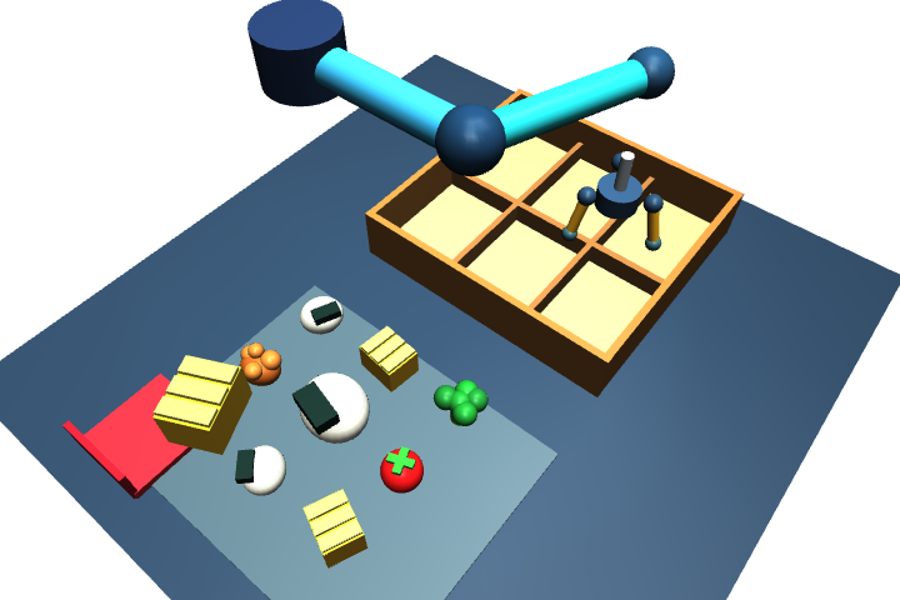

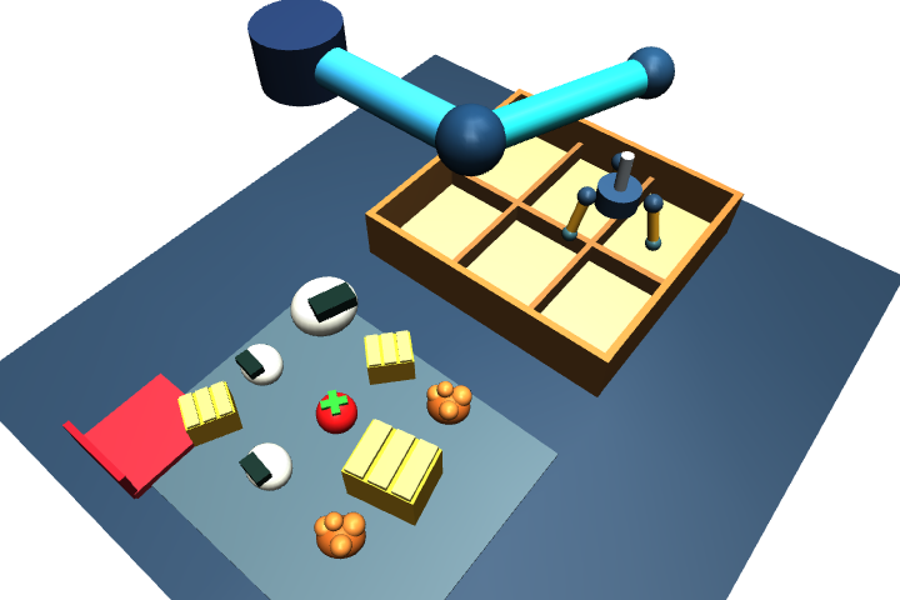

RGB-D size calibration OK {0: {'area_at_1x': 866.0, 'width_at_1x': 33.0, 'reference_item': 0, 'reference_scale': 1.0}, 1: {'area_at_1x': 1051.5, 'width_at_1x': 34.0, 'reference_item': 1, 'reference_scale': 1.0}, 2: {'area_at_1x': 846.0, 'width_at_1x': 36.0, 'reference_item': 2, 'reference_scale': 1.0}, 3: {'area_at_1x': 708.5, 'width_at_1x': 31.07857894897461, 'reference_item': 3, 'reference_scale': 1.0}, 4: {'area_at_1x': 672.0, 'width_at_1x': 29.0, 'reference_item': 5, 'reference_scale': 1.0}}
ID 0, true=1.00, predicted=1.00, limit=1.23, selected=True
ID 4, true=1.55, predicted=1.61, limit=1.23, selected=False
ID 6, true=1.50, predicted=1.59, limit=1.24, selected=False
ID 8, true=1.00, predicted=1.00, limit=1.23, selected=True
ID 9, true=1.00, predicted=1.00, limit=1.24, selected=True
画像検出: 9 / 9


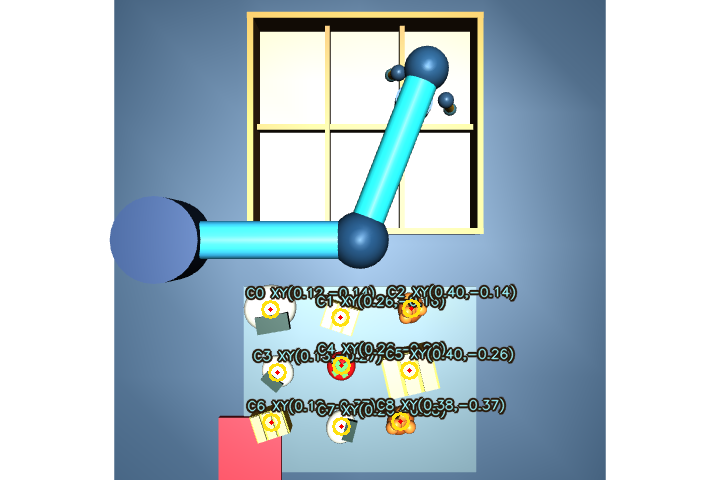

検出したXY[m]: [[0.12047, -0.1388], [0.25982, -0.1581], [0.40484, -0.14006], [0.12997, -0.2722], [0.26137, -0.25884], [0.3987, -0.26054], [0.11813, -0.37285], [0.262, -0.38357], [0.38383, -0.37101]]


In [21]:
from scene_3d import BentoSim, ITEM_CLASSES, ITEM_SCALES, SIZE_LIMITS, SLOTS, RECIPE, EPISODES
from vision_model import calibrate_sizes, estimate_size
from pathlib import Path
import numpy as np
from PIL import Image
from IPython.display import display
assert len(SLOTS)==6 and len(RECIPE)==6
assert RECIPE==(0,1,2,3,0,1)
print("6区画のレシピ:", RECIPE)
sim = BentoSim(size=(720,480))
try:
    display(Image.fromarray(sim.render(top=False)).resize((900,600)))
    sim.reset(1,seed=31531)
    display(Image.fromarray(sim.render(top=False)).resize((900,600)))
    sim.reset(0,seed=31031)
    calib=calibrate_sizes(sim)
    print('RGB-D size calibration OK',calib)
    xy=(.28,-.25)
    for i in [0,4,6,8,9]:
        sim.train_view(i,xy,0.)
        estimated=estimate_size(sim.render_depth(),sim.render_empty_depth(),xy,ITEM_CLASSES[i],calib)
        limit=SIZE_LIMITS[ITEM_CLASSES[i]]
        selected=bool(np.isfinite(estimated) and estimated<=limit-.035)
        print(f'ID {i}, true={ITEM_SCALES[i]:.2f}, predicted={estimated:.2f}, limit={limit:.2f}, selected={selected}')
        should_select=ITEM_SCALES[i]<=limit
        if selected != should_select:
            raise RuntimeError(f'ID {i}のサイズ判定が正しくありません。学習せずにdepth_mask_itemとカメラ設定を確認してください。')
    # 画像全体から食品中心を検出する（真値の食品XYを入力しない）
    # RGB-D画像全体から中心を抽出（シミュレーターの食品XYは入力しない）
    from vision_model import detect_food_centers,draw_detection_overlay
    from scene_3d import SOURCE
    sim.reset(1,31031)
    front=sim.render(top=True);depth=sim.render_depth();bg=sim.render_empty_depth()
    detected,mask=detect_food_centers(front,depth,bg,SOURCE)
    print('画像検出:',len(detected),'/',len(SOURCE))
    import cv2
    from PIL import Image
    display(Image.fromarray(cv2.cvtColor(draw_detection_overlay(front,detected),cv2.COLOR_BGR2RGB)))
    print('検出したXY[m]:',[d['xy'] for d in detected])
finally:
    sim.close()


## STEP 4｜設定：6マス＋画像中心検出（別の結果フォルダー）

`results_bento6_vision/` に新規評価結果を保存します。旧4マス・旧6マスの結果は混ぜません。

In [22]:
from pathlib import Path
import shutil
QUICK_TEST=False  # 提出用120秒動画を生成する。短縮テストはTrue
RESULT_DIR=Path('results_bento6_vision_quick' if QUICK_TEST else 'results_bento6_vision')
RESULT_DIR.mkdir(parents=True,exist_ok=True)
TRAIN_N=700
VAL_N=125
EPOCHS=20
SCENES=4
SEED=31031
# CNNは同じ5クラス・同じアーキテクチャ。旧モデルの重みのみコピー。
old_ckpt=Path('results_bento3d/food_cnn.pt')
new_ckpt=RESULT_DIR/'food_cnn.pt'
if not new_ckpt.exists() and old_ckpt.is_file():
    shutil.copy2(old_ckpt,new_ckpt)
    print('以前のCNN重みをコピーしました:',old_ckpt)
REUSE_MODEL=new_ckpt.is_file()  # 未保存ならFalseで新しく学習
OMNI_ACCOUNT='YOUR_OMNICAMPUS_ACCOUNT'
GITHUB_URL=''
YOUTUBE_URL=''
print('6マス用のモデルを再利用する:',REUSE_MODEL)
print('出力:',RESULT_DIR.resolve())


6マス用のモデルを再利用する: True
出力: /content/results_bento6_vision


## STEP 5｜画像検出→CNN/RGB-D→6区画の動作と評価→日本語音声MP4・PDF

**まず `QUICK_TEST=True` で動作確認**し、本番は `False` に変更してください。

In [23]:
import sys,subprocess
cmd=[sys.executable,'-u','run_project.py','--out',str(RESULT_DIR),
'--train-n',str(TRAIN_N),'--val-n',str(VAL_N),'--epochs',str(EPOCHS),
'--scenes',str(SCENES),'--seed',str(SEED),'--account',OMNI_ACCOUNT,
'--github',GITHUB_URL,'--youtube',YOUTUBE_URL]
if REUSE_MODEL:
    if not (RESULT_DIR/'food_cnn.pt').is_file():
        raise FileNotFoundError('REUSE_MODEL=Trueですがfood_cnn.ptがありません。Falseに変更してください。')
    cmd.append('--reuse')
if QUICK_TEST:cmd.append('--quick')
print('RUN:', ' '.join(cmd), flush=True)
with open('bento_debug.log','w',encoding='utf8') as log:
    proc=subprocess.Popen(cmd,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
    for line in proc.stdout:
        print(line,end='',flush=True)
        log.write(line);log.flush()
    ret=proc.wait()
if ret:raise RuntimeError('実行失敗。上に表示されたTracebackと bento_debug.log の末尾を確認してください。')
print('ALL DONE')

RUN: /usr/bin/python3 -u run_project.py --out results_bento6_vision --train-n 700 --val-n 125 --epochs 20 --scenes 4 --seed 31031 --account YOUR_OMNICAMPUS_ACCOUNT --github  --youtube  --reuse
PyTorch 2.11.0+cpu; training device=cpu
Starting 3D MuJoCo SCARA / SIX-compartment (2x3) workbench
STUDIO PREVIEW: clean scene and 3-finger claw preview saved.
Reusing saved CNN checkpoint
Training or checkpoint loading complete. Starting fresh 3D evaluation...
RGB-D size calibration: {0: {'area_at_1x': 866.0, 'width_at_1x': 33.0, 'reference_item': 0, 'reference_scale': 1.0}, 1: {'area_at_1x': 1051.5, 'width_at_1x': 34.0, 'reference_item': 1, 'reference_scale': 1.0}, 2: {'area_at_1x': 846.0, 'width_at_1x': 36.0, 'reference_item': 2, 'reference_scale': 1.0}, 3: {'area_at_1x': 708.5, 'width_at_1x': 31.07857894897461, 'reference_item': 3, 'reference_scale': 1.0}, 4: {'area_at_1x': 672.0, 'width_at_1x': 29.0, 'reference_item': 5, 'reference_scale': 1.0}}
RGB-D size self-check (isolated views): {'eval

## STEP 5.5｜音声生成だけ失敗した場合の復旧（学習・評価はやり直さない）

`results_bento6/summary.json`と3D録画フレームがある場合にだけ使います。話速を変えず、長すぎる台詞は短い台詞へ自動切替します。


In [24]:
from pathlib import Path
import json, zipfile
from make_video import make_video
from make_report import make_report

root = Path('results_bento6_vision')
summary_path = root / 'summary.json'
if not summary_path.is_file():
    raise FileNotFoundError('先に学習と評価を完了してください: '+str(summary_path))
summary = json.loads(summary_path.read_text(encoding='utf-8'))
for name in ('frames_ai','frames_baseline'):
    n = len(list((root/name).glob('frame_*.jpg')))
    print(name, '実録画フレーム数:', n)
    if n < 12: raise RuntimeError(f'{name} が不足しています。評価録画を確認してください。')

video = root/'PAI_Bento3D_120s.mp4'
print('学習・3D評価は実行しません。既存録画から音声動画を再作成します。')
seconds=make_video(root,summary,video)
print(f'音声付きMP4完成: {video} / {seconds:.1f}秒')

account = globals().get('OMNI_ACCOUNT','YOUR_OMNICAMPUS_ACCOUNT')
github = globals().get('GITHUB_URL','')
youtube = globals().get('YOUTUBE_URL','')
pdf=root/f'説明資料_PAI最終課題_{account}.pdf'
make_report(summary_path,pdf,account,github,youtube)
print('PDF完成:',pdf)

archive=root/'PAI_Bento3D_Results.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for file in sorted(root.iterdir()):
        if file.is_file() and file!=archive:
            z.write(file,file.name)
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None
print('ZIP完成:',archive)
print('ALL DONE')

frames_ai 実録画フレーム数: 324
frames_baseline 実録画フレーム数: 324
学習・3D評価は実行しません。既存録画から音声動画を再作成します。
音声付きMP4完成: results_bento6_vision/PAI_Bento3D_120s.mp4 / 120.0秒
PDF完成: results_bento6_vision/説明資料_PAI最終課題_YOUR_OMNICAMPUS_ACCOUNT.pdf
ZIP完成: results_bento6_vision/PAI_Bento3D_Results.zip
ALL DONE


## STEP 6｜6区画の正誤・画像中心座標の検出誤差・120秒MP4再生

In [25]:
import json, pandas as pd
from IPython.display import Video,display
summary_path=RESULT_DIR/'summary.json'
if summary_path.exists():
    summary=json.loads(summary_path.read_text(encoding='utf8'))
    for mode in ['baseline','ai_no_size','ai','oracle']:
        m=summary[mode]
        print(mode,'item_success=',round(m['item_success_rate']*100,1),'%',
              'six_slot_success=',round(m['compartment_success_rate']*100,1),'%',
              'oversize_reject=',m.get('oversize_reject_recall'))
    print('RGB-D isolated validation',summary.get('rgbd_size_validation'))
    audit=pd.read_csv(RESULT_DIR/'compartment_audit.csv')
    display(audit[(audit['mode']=='ai') & (audit['scene']==1)][['slot','recipe_class','actual','expected','correct']])
    detail=pd.read_csv(RESULT_DIR/'evaluation_detail.csv')
    print('Large rice (ID 4) / large omelette (ID 6):')
    display(detail[(detail['item_id'].isin([0,4,6])) & (detail['mode']=='ai')][['scene','item_id','true_class','size_true_x','size_est_x','action','correct']])
else:print('先にSTEP 5を実行してください')
video=RESULT_DIR/'PAI_Bento3D_120s.mp4'
if video.exists():display(Video(str(video),embed=True))
else:print('短縮テストまたは未実行のためMP4はまだありません')

print('画像中心検出の平均位置誤差(m):',summary.get('localization_mae_m'))
print('画像からの中心検出オーバーレイ:',RESULT_DIR/'detection_overlay_scene1.png')
from PIL import Image
from IPython.display import display
if (RESULT_DIR/'detection_overlay_scene1.png').exists():
    display(Image.open(RESULT_DIR/'detection_overlay_scene1.png'))


Output hidden; open in https://colab.research.google.com to view.

## STEP 6.5｜学習・評価をせず日本語音声付き動画だけ再生成（必要な場合）

In [26]:
# gTTS通信エラーなどで動画作成だけ失敗した場合に実行してください。
# frames_ai/ と frames_baseline/ と summary.json が必要です。
# !python make_video.py --results results_bento6


## STEP 7｜公開URLを入れてPDFのみ更新（再学習なし）

In [27]:
# STEP 4でGITHUB_URL、YOUTUBE_URL、OMNI_ACCOUNTを書き直して設定セルを実行後、こちらを実行。
from make_report import make_report
if (RESULT_DIR/'summary.json').exists():
    pdf_path=RESULT_DIR/f'説明資料_PAI最終課題_{OMNI_ACCOUNT}.pdf'
    make_report(RESULT_DIR/'summary.json',pdf_path,OMNI_ACCOUNT,GITHUB_URL,YOUTUBE_URL)
    print('Updated PDF',pdf_path)
else:print('評価結果のsummary.jsonがありません')

Updated PDF results_bento6_vision/説明資料_PAI最終課題_YOUR_OMNICAMPUS_ACCOUNT.pdf


## STEP 8｜6マス版の評価・音声付きMP4・PDFをZIPでダウンロード


In [28]:
from pathlib import Path
import zipfile
zip_path=RESULT_DIR/'PAI_Bento3D_Results.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as zz:
    for path in RESULT_DIR.iterdir():
        if path.is_file() and path!=zip_path:
            zz.write(path,path.name)
print('ZIP ready:',zip_path,'bytes=',zip_path.stat().st_size)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print('Colab上では左側のファイル一覧からZIPをダウンロードしてください')

ZIP ready: results_bento6_vision/PAI_Bento3D_Results.zip bytes= 6876792


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:

# ============================================================
# GitHub提出用ファイル一式を作成・ダウンロード
# 6マスお弁当 / CNN / RGB-D / 中心座標検出 / 3本爪
# ============================================================

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files
import json

ROOT = Path("/content")
RESULT = ROOT / "results_bento6_vision"
ZIP_PATH = ROOT / "Bento6_GitHub_Submission.zip"

# 1. GitHubに必要なPythonソース
required = [
    "scene_3d.py",
    "vision_model.py",
    "run_project.py",
    "make_video.py",
    "make_report.py",
]

missing = [f for f in required if not (ROOT / f).is_file()]

if missing:
    raise FileNotFoundError(
        f"必要なコードが見つかりません: {missing}"
    )

# 2. READMEに実測値を記載
summary_path = RESULT / "summary.json"

if summary_path.exists():
    summary = json.loads(
        summary_path.read_text(encoding="utf-8")
    )

    def percent(method, key="item_success_rate"):
        value = summary.get(method, {}).get(key)
        return f"{value * 100:.1f}%" if value is not None else "未計測"

    results_text = f"""
## Evaluation results

- Scenes: {summary.get("scenes", "N/A")}
- Baseline success rate: {percent("baseline")}
- CNN without size judgment: {percent("ai_no_size")}
- Proposed AI success rate: {percent("ai")}
- Oracle reference: {percent("oracle")}
- Oversize rejection recall: {percent("ai", "oversize_reject_recall")}

Results are from the simulation described in `results/summary.json`.
"""
else:
    results_text = """
## Evaluation results

Run the notebook to generate `results/summary.json`.
"""

readme = f"""# AI Bento Plating Robot 3D — Six Compartments

## Overview

MuJoCo-based 3D robotic bento plating system.

Features:
- Six-compartment bento box (2 × 3)
- Normal-size and oversized food items
- CNN food classification
- RGB-D food size estimation
- Image-based food center localization
- Three-finger robotic claw
- Baseline vs AI comparison
- Japanese-narrated 120-second video

## Main files

- `scene_3d.py` — MuJoCo scene and robot
- `vision_model.py` — CNN and RGB-D vision
- `run_project.py` — Training and evaluation
- `make_video.py` — Video and narration
- `make_report.py` — PDF report

## Reproduction

Install dependencies using `requirements.txt`, then run:

```bash
python run_project.py --out results_bento6_vision --train-n 500 --val-n 125 --epochs 10 --scenes 4 --seed 31031
```

{results_text}

## Limitations

The robot uses a simplified kinematic grasp constraint.
Image localization uses known supply-cell regions.
The system has been evaluated in simulation, not on a real robot.

## Demo

Add the public YouTube video URL here.
"""

# 3. 依存ライブラリ
requirements_path = ROOT / "requirements.txt"

if requirements_path.is_file():
    requirements = requirements_path.read_text(encoding="utf-8")
else:
    requirements = """numpy
torch
mujoco
opencv-python-headless
Pillow
scipy
matplotlib
reportlab
gTTS
imageio
imageio-ffmpeg
"""

# 4. ZIPにまとめる
with ZipFile(ZIP_PATH, "w", ZIP_DEFLATED) as z:

    z.writestr("README.md", readme)
    z.writestr("requirements.txt", requirements)

    z.writestr(
        ".gitignore",
        "__pycache__/\n*.pyc\n.ipynb_checkpoints/\n"
        "results_bento6_vision/frames_*/\n*.pt\n*.mp4\n"
    )

    # Pythonコード
    for name in required:
        z.write(ROOT / name, name)

    # テストコード
    for p in sorted(ROOT.glob("test_*.py")):
        z.write(p, p.name)

    # Notebookが/contentに存在する場合は追加
    notebooks = sorted(ROOT.glob("*.ipynb"))
    for p in notebooks:
        z.write(p, p.name)

    # 実測評価結果（大量の録画フレームは除外）
    result_names = [
        "summary.json",
        "evaluation_detail.csv",
        "localization_detail.csv",
        "compartment_audit.csv",
        "size_validation.csv",
        "size_calibration.json",
        "detection_overlay_scene1.png",
    ]

    for name in result_names:
        p = RESULT / name
        if p.is_file():
            z.write(p, f"results/{name}")

# 5. ZIPの整合性確認
with ZipFile(ZIP_PATH) as z:
    assert z.testzip() is None
    print("===== GitHub提出ファイル =====")
    for name in z.namelist():
        print(name)

print()
print("ZIP作成成功:", ZIP_PATH)
print("サイズ:", round(ZIP_PATH.stat().st_size / 1024**2, 2), "MB")

# 6. 自動ダウンロード
files.download(str(ZIP_PATH))


===== GitHub提出ファイル =====
README.md
requirements.txt
.gitignore
scene_3d.py
vision_model.py
run_project.py
make_video.py
make_report.py
results/summary.json
results/evaluation_detail.csv
results/localization_detail.csv
results/compartment_audit.csv
results/size_validation.csv
results/size_calibration.json
results/detection_overlay_scene1.png

ZIP作成成功: /content/Bento6_GitHub_Submission.zip
サイズ: 0.19 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>